# Flux: USTAR threshold detection for both gas analysers

# About this notebook

At night the measured `NEE` is too low when turbulence is weak, because part of the respired CO2
leaves the site below the sensor or stays in the canopy air. Level 3.3 of the flux chain therefore
removes records with a friction velocity `USTAR` below a threshold, at three thresholds that give
the scenarios `CUT_16`, `CUT_50` and `CUT_84` (see the page on Level 3.3 of the documentation).

This notebook detects the thresholds that FP2026.2 uses, one set per gas analyser, and documents
the checks behind the choice:

1. where the thresholds of FP2026.1 came from, and why they are low;
2. the detection on the current data with the ONEFlux moving point method, and with the other
   methods for comparison;
3. whether the detection finds a known threshold in synthetic data;
4. how night-time `NEE` behaves above the thresholds;
5. why the filter also applies by day;
6. how many records each threshold keeps, and what it does to the night-time respiration;
7. how the thresholds and the annual sums compare with FLUXNET;
8. whether pooling the data of several years, or of several seasons, gives a better threshold, and
   whether the threshold changes from year to year;
9. how night `NEE` compares with the respiration of the daytime partitioning;
10. whether the high night `NEE` at high `USTAR` is CO2 flushed out of the canopy.

The input is `NEE` after Level 3.2, before the USTAR filter. The notebook prepares it itself: it runs
Levels 2 to 3.2 of the flux chains of both analysers, with the same diive functions and settings as
the `05` notebooks, from the same input files. A settings check stops the notebook when the settings
here and in the `05` notebooks differ. Level 3.2 does not depend on the thresholds, so the detection
runs before the chain: this notebook first, then the thresholds declared under Settings go into
`USTAR_THRESHOLDS` of the `05` notebooks, then `05` runs. The notebook is run again whenever the
settings of Levels 2 to 3.2 change.

Sections 6, 7, 9 and 10 also compare with results of the full chain (night-time respiration, annual
sums, daytime partitioning). These are read from the `05` outputs when they exist, and the tables
under Prepare the input show which thresholds that run applied. Without them these parts are
skipped.

# Main findings

- **FP2026.1.** Its thresholds (0.272, 0.304 and 0.340 m s⁻¹) came from two REddyProc runs with 30
  instead of 20 `USTAR` classes and a shortened plateau test. diive repeats both runs exactly. With the
  REddyProc defaults, the same data give thresholds of about 0.3 to 0.6 m s⁻¹ per year.
- **FP2026.2.** The thresholds come from the ONEFlux moving point method, one set per analyser:
  0.42, 0.52 and 0.65 m s⁻¹ for the LI-7200 and 0.31, 0.44 and 0.55 m s⁻¹ for the LI-7500
  (`CUT_16`, `CUT_50`, `CUT_84`). Of the ONEFlux methods, it gives the lowest thresholds; the change
  point method gives medians of 0.59 and 0.64 m s⁻¹.
- **The detection works, but detects too low on noisy data.** In synthetic data it finds a clear
  threshold. With the scatter of the real data and a gradual rise of `NEE`, all methods return a
  threshold below the true one, the moving point methods most of all. A detected threshold is
  therefore a lower bound.
- **No plateau.** Night `NEE` keeps rising with `USTAR` up to about 0.9 to 1.0 m s⁻¹, in both analysers
  and in every temperature class.
- **By day.** Daytime records at low `USTAR` show less uptake in sun and more at dawn and dusk than
  well-mixed records under the same conditions, so the filter also applies by day.
- **Cost.** At the FP2026.2 median thresholds about 20 % of the night half-hours stay measured
  (FP2026.1: 28 to 37 %), and the night-time respiration estimated from them is 20 to 26 % higher.
- **FLUXNET.** Over 2005-2024 FLUXNET shows more net uptake than this product. The difference lies
  in the LI-7500 years, mainly at night, where its self-heating correction makes the nights lower.
  From 2016, with similar thresholds, the period means of the two agree within about 35 gC m⁻² per
  year.
- **Constant threshold.** The thresholds of single years differ by no more than the bootstrap
  spread within one year, so a change from year to year cannot be detected.
- **One set for both analysers.** On one record of the site (LI-7500 to 2015, LI-7200 from 2016)
  the moving point method gives 0.35, 0.49 and 0.60 m s⁻¹. On the records both analysers measured in
  2016-2017 they give the same threshold within 0.01 m s⁻¹, and night `NEE` rises with `USTAR` in the
  same way in both. The difference between the two per-analyser sets is therefore not an effect of
  the instruments.
- **Pooling raises the threshold.** With the data of more years per detection, the moving point
  method returns higher thresholds, and with all years pooled it finds none from April to September.
  Pooling across seasons gives no threshold that agrees between the two analysers.
- **Daytime partitioning.** Night `NEE` reaches the respiration of the daytime method at a `USTAR`
  of about 0.7 to 0.9 m s⁻¹ and exceeds it above. At the FP2026.2 median thresholds the measured
  nights lie 7 % (LI-7200) and 2 % (LI-7500) below it. The daytime respiration takes its temperature
  sensitivity from the night records above the threshold, so it moves with the threshold applied in
  the chain: the kept nights matched it near `CUT_16` with the FP2026.1 thresholds and near `CUT_84`
  (LI-7200) and `CUT_50` (LI-7500) with those of FP2026.2. It cannot decide the threshold.
- **Flushing.** In the LI-7500 data from 0.7 m s⁻¹, and in the LI-7200 data above 0.9 m s⁻¹, night
  `NEE` exceeds the daytime respiration more after calm hours. This points to CO2 released from the
  canopy air, which the storage term from one height does not capture.

</br>

# Settings

In [1]:
from pathlib import Path

DATADIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow")
# Input: the input files of the 05 notebooks. This notebook runs Levels 2 to 3.2 of both flux
# chains itself, with the settings below, copied from the Settings and Step 4 of the 05 notebooks.
# The settings check under "Prepare the input" compares them with the 05 notebooks.
CHAIN_NOTEBOOKS = {'IRGA72': Path("IRGA72") / "05_FPPC_IRGA72_NEE_2016-2026.09.ipynb",
                   'IRGA75': Path("IRGA75") / "05_FPPC_IRGA75_NEE_OPCO_2004-2017.ipynb"}  # next to this notebook
CHAIN_INPUT = {
    'IRGA72': dict(
        source=r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet",
        corrected_fluxcol=None,  # FC of the LI-7200 needs no correction
        years=None,  # the whole record
        signal_strength={'apply': True, 'signal_strength_col': 'CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN',
                         'method': 'discard below', 'threshold': 60},
        remove_dates=[
            ['2016-01-11', '2016-01-22'], ['2016-01-30 22:45', '2016-02-02 19:45'],
            ['2016-02-03 14:15', '2016-02-03 16:45'], ['2016-02-04 20:15', '2016-02-06 09:15'],
            ['2016-02-15 00:45', '2016-02-16 06:15'], ['2016-02-20 16:45', '2016-02-22 14:15'],
            ['2016-02-29 07:45', '2016-02-29 21:15'], ['2016-03-01', '2016-05-26 07:45'],
            ['2018-05-17 07:15', '2018-05-17 16:45'], ['2018-05-18 07:45', '2018-05-19 11:45'],
            ['2018-12-30', '2019-01-10'], ['2020-11-08', '2020-11-27'], ['2020-12-04', '2020-12-06'],
            ['2021-04-28 20:15', '2021-05-20 11:15'], ['2021-05-21 21:45', '2021-05-27 11:45'],
            ['2023-08-11 10:45', '2023-08-14 13:15'], ['2026-01-15', '2026-02-04']],
        opco_sigma=None,
        storage_screen=None),  # all readings used for the storage term
    'IRGA75': dict(
        source=r"30_FLUX_POST-PROCESSING_CHAIN\IRGA75\01_FPPC_IRGA75_OPEN-PATH_CORRECTION_2004-2017_2019.parquet",
        corrected_fluxcol='FC_L1.1_OPCO',  # the flux corrected with opco in notebook 01
        years=list(range(2004, 2018)),
        signal_strength={'apply': True, 'signal_strength_col': 'CUSTOM_AGC_IRGA75_MEAN',
                         'method': 'discard outside', 'threshold': (40, 90)},
        remove_dates=[['2004-12-01', '2004-12-15'], ['2013-11-16', '2013-11-23'],
                      ['2014-11-09', '2014-11-12'], ['2014-11-24', '2014-12-07']],
        opco_sigma=1.0,  # uncertainty of the opco correction, umol m-2 s-1
        # readings used for the storage term: AGC up to agc_max, no rain in the previous rain_hours,
        # RH below rh_max, not the first skip_after_gaps records after a gap (Settings of 05)
        storage_screen=dict(agc_max=55, rain_hours=3, rh_max=99.5, skip_after_gaps=3)),
}
METEOFILE = r"10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09.parquet"  # for PREC
PREC, RH = 'PREC_TOT_T1_47_1', 'RH_T1_47_1_HOMOGENIZED'
FLUXCOL = 'FC'
SITE_LAT, SITE_LON, UTC_OFFSET = 47.478333, 8.364389, 1
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1, by day and by night
LEVEL2_COMMON = {
    'raw_data_screening_vm97': {'apply': True, 'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': False, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}
CO2_CONC = 'CO2_MOLAR_DENSITY'  # for the storage term (Level 3.1)
ABSLIM = (-50, 50)  # umol m-2 s-1
HAMPEL_TESTS = [  # in this order: HAMPEL, HAMPEL_2, HAMPEL_3
    dict(window_length=48 * 13, n_sigma=5.5, use_differencing=True, separate_day_night=True, repeat=True),
    dict(window_length=48 * 13, n_sigma=5.5, use_differencing=False, by_time_of_day=True,
         time_of_day_slots=1, min_records=10, separate_day_night=True, repeat=True),
    dict(window_length=48 * 31, n_sigma=7, use_differencing=False, by_time_of_day=True,
         time_of_day_slots=1, min_records=10, separate_day_night=True, repeat=True),
]
RANDUNC_COL = 'FC_RANDUNC_HF'  # random uncertainty of FC from EddyPro
NIGHT_Z = 4  # NEGNIGHT: below -NIGHT_Z times the uncertainty of the record
NIGHTS_Z, NIGHTS_AUTOCORR, NIGHTS_MIN_RECORDS = 3, 0.2, 6  # NEGNIGHTS, LI-7500 only

# Results of the full chain (the 05 outputs), read when they exist: the respiration, the annual sums
# and the daytime partitioning that sections 6 to 10 compare with. Without them those parts are
# skipped; the detection does not use them.
CHAIN_OUTPUT = {'IRGA72': r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\05_FPPC_IRGA72_NEE_2016-2026.09.parquet",
                'IRGA75': r"30_FLUX_POST-PROCESSING_CHAIN\IRGA75\05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet"}
ANALYSERS = {'IRGA72': 'LI-7200', 'IRGA75': 'LI-7500'}
COMPLETE_YEARS = {'IRGA72': (2016, 2025), 'IRGA75': (2004, 2017)}  # for per-year counts and sums

# FLUXNET ONEFlux v1.3 for CH-Lae (LI-7500 to 2015, LI-7200 from 2016). Missing values are -9999,
# timestamps are TIMESTAMP_START. The BIF file holds the USTAR thresholds and the REF selection.
FLUXNET_DIR = Path(r"F:\Sync\luhk_work\sites\LAE\Data\Datasets\EUF_CH-Lae_FLUXNET_2004-2024_v1.3_r1")
FLUXNET_HH = "EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1.csv"
FLUXNET_YY = "EUF_CH-Lae_FLUXNET_FLUXMET_YY_2004-2024_v1.3_r1.csv"
FLUXNET_BIF = "EUF_CH-Lae_FLUXNET_BIF_2004-2024_v1.3_r1.csv"
FLX_MISSING = -9999

# Columns: NEE after Level 3.2 (quality flags 0 and 1, before the USTAR filter), prepared below, the
# USTAR of the analyser's own Level-1 run, and the meteo of the chain input.
NEE, USTAR, ZL = 'NEE_L3.1_L3.2_QCF', 'USTAR', 'ZL'
TA, SW_IN, VPD = 'TA_T1_47_1_HOMOGENIZED_gfXG', 'SW_IN_T1_47_1_gfXG', 'VPD_T1_47_1_HOMOGENIZED'
NIGHTTIME = 'NIGHTTIME'  # night flag of the chain
NIGHT_SW_IN = 10  # W m-2, night as the detection defines it

# Detection of FP2026.2: ONEFlux moving point method (Papale et al. 2006) in diive, 100 bootstrap
# draws per year, CUT from the draws of all years. Only the moving point method is used: of the
# methods that detect a threshold at this site, it gives the lowest one.
DETECTION = dict(mode='oneflux_mp', n_iter=100, random_state=42, percentiles=(16, 50, 84))

# The thresholds written into the chain notebooks (USTAR_THRESHOLDS in 05_FPPC_*_NEE), CUT_16/50/84
# in m s-1. They come from the detection below; the integrity check compares them with it.
USTAR_THRESHOLDS = {'IRGA72': [0.415500, 0.523000, 0.645100],
                    'IRGA75': [0.309900, 0.435600, 0.550600]}
THRESHOLD_TOLERANCE = 0.005  # m s-1

# FP2026.1: one set for both analysers, from two REddyProc runs in R (L3.3 page of the docs).
USTAR_THRESHOLDS_FP1 = [0.271619922, 0.303628125, 0.339684084]
_old = r"30_FLUX_POST-PROCESSING_CHAIN"
FP1_RUNS = {
    'IRGA72': dict(input=_old + r"\IRGA72\USTAR_DETECTION_2016-2024\14_IRGA72_SUBSET_NEE_QCF11_2016-2024.csv",
                   result=_old + r"\IRGA72\USTAR_DETECTION_2016-2024\16_USTAR-THRESHOLDS_NEE_QCF11_IRGA72_2016-2024_RP-20251113112030.csv",
                   first='2016-01-01 00:30', last='2025-01-01 00:00', ustar_classes=30, plateau_fwd=9),
    'IRGA75': dict(input=_old + r"\IRGA75\USTAR_DETECTION_2005-2019\04_IRGA75_SUBSET_NEE_QCF10_2005-2019.csv",
                   result=_old + r"\IRGA75\USTAR_DETECTION_2005-2019\06_IRGA75_USTAR-THRESHOLDS_NEE_QCF10_2005-2019_RP-20251113130417.csv",
                   first='2005-01-01 00:30', last='2020-01-01 00:00', ustar_classes=30, plateau_fwd=8),
}

# Synthetic test: true respiration with a known USTAR effect, on the real USTAR, TA and gaps of the
# LI-7200 years.
SYNTH_ANALYSER = 'IRGA72'
SYNTH_E0, SYNTH_RREF = 150.0, 3.5  # K, umol m-2 s-1 at 10 degC

# Thresholds compared for the records kept and the respiration.
COMPARE = {'FP2026.1 CUT_50': USTAR_THRESHOLDS_FP1[1], '0.40': 0.40, '0.70': 0.70}
TREF, T0 = 15.0, -46.02  # Lloyd-Taylor, as the night-time partitioning of ONEFlux
GC = 12.011e-6 * 1800  # umol m-2 s-1 in one half-hour -> gC m-2

# Pooling (section 8): the moving point method on the data of several years, or of all years with
# other seasons. Seasons are lists of months; ONEFlux uses calendar quarters.
SEASONS = {'quarters': [[1, 2, 3], [4, 5, 6], [7, 8, 9], [10, 11, 12]],
           'leaf-off, leaf-on': [[11, 12, 1, 2, 3, 4], [5, 6, 7, 8, 9, 10]],
           'one season': [list(range(1, 13))]}
POOL_YEARS = (1, 3, 5)  # years of data per detection, centred on the year
POOL_DRAWS = 100  # bootstrap draws per detection

# Daytime-method RECO (section 9) and the flush test (section 10)
RECO_DT = 'RECO_DT_OF_CUT_50'  # daytime partitioning of the chain (Lasslop et al. 2010)
STORAGE = 'SC_SINGLE_gfRMED_L3.1'  # storage term of the chain, from the concentration at one height
LEAF_ON = [5, 6, 7, 8, 9, 10]  # months
PREVIOUS_HOURS = 3  # window for the mean USTAR before a record

# One set for both analysers (section 11): the moving point method on one record of the site, the
# LI-7500 to 2015 and the LI-7200 from 2016, so the closed path supplies the overlap. OVERLAP is the
# period in which both analysers measured.
MERGED_RECORD = {'IRGA75': ('2004', '2015'), 'IRGA72': ('2016', '2025')}
OVERLAP = ('2016-01-11', '2017-12-12')

# Imports

In [2]:
import importlib.metadata
import json
import re
import textwrap
import time
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import diive as dv

from diive.flux.lowres.ustar_detection import UstarThresholdDetection
from diive.flux.postprocessingchain import (init_flux_data, make_level32_detector, nighttime_uncertainty,
                                            run_level2, run_level31, run_level32)
from diive.flux.lowres.ustar_mp_detection import UstarMovingPointDetection
from diive.flux.lowres.ustar_cp_detection import UstarChangePointDetection
from diive.flux.lowres.ustar_reddyproc_detection import UstarReddyProcDetection

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=RuntimeWarning)
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START:%Y-%m-%d %H:%M:%S}")
for _p in ('diive', 'pandas', 'numpy'):
    print(f"{_p} version: v{importlib.metadata.version(_p)}")

Last run: 2026-11-01 20:19:00
diive version: v0.93.0
pandas version: v3.0.3
numpy version: v2.4.6


# Helpers

In [3]:
def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure — {text}", width), fontsize=9, ha='left', x=0.005)


def styled(data, caption, fmt="{:.2f}", subset=None, cmap="RdBu_r", center=True):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values."""
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {c: fmt.get(c, "{:.2f}") for c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None or not numeric:
        return styler
    values = data[subset] if subset is not None else data[numeric]
    limits = {}
    if center:
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, text_color_threshold=0.4, **limits)


def full_years(df):
    """`df` on the complete half-hourly grid of its calendar years, as the detection expects."""
    grid = pd.date_range(f"{df.index[0].year}-01-01 00:15", f"{df.index[-1].year}-12-31 23:45",
                         freq='30min', name='TIMESTAMP_MIDDLE')
    out = df.reindex(grid)
    out.index.freq = '30min'
    return out


DET_COLS = dict(nee_col=NEE, ta_col=TA, ustar_col=USTAR, swin_col=SW_IN)


def lloyd_taylor(t, e0):
    return np.exp(e0 * (1.0 / (TREF - T0) - 1.0 / (t - T0)))


def reco_estimate(frame, nee_night, e0_by_year):
    """Night-time respiration at every half-hour: reference respiration per day from the measured
    night NEE within +-7 days (widened to 15, 30 and 60 days for at least 10 records), times
    Lloyd-Taylor with the E0 of the year from the chain's night-time partitioning."""
    out = pd.Series(np.nan, index=frame.index)
    day_no = (frame.index - frame.index[0]).days
    for yr in np.unique(frame.index.year):
        k = frame.index.year == yr
        y, t, dd = nee_night[k], frame.loc[k, TA], day_no[k]
        ok = y.notna().to_numpy()
        yy, ff, ddd = y.to_numpy()[ok], lloyd_taylor(t, e0_by_year[yr]).to_numpy()[ok], dd[ok]
        rref = {}
        for day in np.unique(dd):
            for half in (7, 15, 30, 60):
                w = np.abs(ddd - day) <= half
                if w.sum() >= 10:
                    rref[day] = (yy[w] * ff[w]).sum() / (ff[w] ** 2).sum()
                    break
        out[k] = pd.Series(dd).map(rref).to_numpy(dtype=float) * lloyd_taylor(t, e0_by_year[yr]).to_numpy()
    return out

</br>

# Prepare the input

Levels 2 to 3.2 of the flux chain of each analyser, as in its `05` notebook: the quality flags of
Level 2, the storage term of Level 3.1, and the outlier tests of Level 3.2 (`MANUAL`, `ABSLIM`,
`HAMPEL`, `HAMPEL_2`, `HAMPEL_3`, `NEGNIGHT`, and `NEGNIGHTS` for the LI-7500). The LI-7500 flux is
the one corrected with opco in notebook `01`. Plots of the single tests are in the `05` notebooks.

In [4]:
def prepare_level32(analyser):
    """Levels 2 to 3.2 of the flux chain of `analyser`, as in its 05 notebook, without plots.
    Returns the merged frame of the chain."""
    _c = CHAIN_INPUT[analyser]
    _df = dv.load_parquet(filepath=DATADIR / _c['source'])
    _df = _df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in _df.columns])
    if _c['years']:
        _df = _df.loc[_df.index.year.isin(_c['years'])].copy()
    if _c['corrected_fluxcol']:
        _df[FLUXCOL] = _df[_c['corrected_fluxcol']]  # the chain processes the corrected flux as FC
    _data = init_flux_data(df=_df, fluxcol=FLUXCOL, site_lat=SITE_LAT, site_lon=SITE_LON, utc_offset=UTC_OFFSET,
                           nighttime_threshold=NIGHTTIME_THRESHOLD, daytime_accept_qcf_below=ACCEPT_QCF_BELOW,
                           nighttime_accept_qcf_below=ACCEPT_QCF_BELOW)
    _data = run_level2(_data, signal_strength=_c['signal_strength'], **LEVEL2_COMMON)
    _l31 = dict(gapfill_storage_term=True, set_storage_to_zero=False, screen_storage_term=True,
                concentration_col=CO2_CONC)
    _ss = _c['storage_screen']
    if _ss:
        _prec = pd.read_parquet(DATADIR / METEOFILE, columns=[PREC])[PREC].reindex(_df.index)
        _rain = _prec.rolling(2 * _ss['rain_hours'], min_periods=1).sum() > 0
        _agc = _df[_c['signal_strength']['signal_strength_col']]
        _l31.update(concentration_valid=(_agc <= _ss['agc_max']) & ~_rain & (_df[RH] < _ss['rh_max']),
                    restart_screening={'skip_after_gaps': _ss['skip_after_gaps']})
    _data = run_level31(_data, **_l31)
    _data, _sod = make_level32_detector(_data)
    _sod.flag_manualremoval_test(remove_dates=_c['remove_dates'], showplot=False, verbose=False)
    _sod.addflag()
    _sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=False, verbose=False)
    _sod.addflag()
    for _kw in HAMPEL_TESTS:
        _sod.flag_outliers_hampel_test(**_kw, showplot=False, verbose=False)
        _sod.addflag()
    # NEGNIGHT: uncertainty of a record = the larger of the EddyPro uncertainty (FS) and the median PAS20
    # of the nighttime records of the same calendar month, over all years; for the LI-7500 combined in
    # quadrature with the uncertainty of the opco correction.
    _sig = nighttime_uncertainty(_data, _sod, randunc_col=RANDUNC_COL, ta=TA, vpd=VPD, swin=SW_IN)
    _night = (_data.fpc_df['NIGHTTIME'].reindex(_sig.index) == 1) & _sig['PAS20'].notna()
    _pas20 = _sig.loc[_night, 'PAS20'].groupby(_sig.index[_night].month).median()
    _typical = pd.Series(_sig.index.month, index=_sig.index).map(_pas20).where(_sig['PAS20'].notna())
    _unc = np.fmax(_sig['FS'], _typical)
    if _c['opco_sigma']:
        _unc = np.sqrt(_unc ** 2 + _c['opco_sigma'] ** 2)
    _unc = _unc.rename('NIGHT_UNC')
    _sod.flag_outliers_negative_night_test(uncertainty=_unc, z=NIGHT_Z, showplot=False, verbose=False)
    _sod.addflag()
    if _c['opco_sigma']:
        # NEGNIGHTS: the record uncertainty widened for the lag-1 autocorrelation within a night
        _nights_unc = (_unc * np.sqrt((1 + NIGHTS_AUTOCORR) / (1 - NIGHTS_AUTOCORR))).rename('NIGHT_UNC')
        _sod.flag_outliers_negative_nights_test(uncertainty=_nights_unc, z=NIGHTS_Z, min_records=NIGHTS_MIN_RECORDS,
                                                systematic=_c['opco_sigma'], showplot=False, verbose=False)
        _sod.addflag()
    _data = run_level32(_data, outlier_detector=_sod)
    return _data.merged_df(verbose=0)


prepared = {}
data = {}
_paths = {}
for _a in CHAIN_INPUT:
    _t = time.time()
    prepared[_a] = prepare_level32(_a)
    data[_a] = full_years(prepared[_a][[NEE, NIGHTTIME, USTAR, ZL, TA, SW_IN, VPD, STORAGE]])
    _paths[f"{_a} chain input"] = DATADIR / CHAIN_INPUT[_a]['source']
    print(f"{ANALYSERS[_a]}: Levels 2 to 3.2 in {time.time() - _t:.0f} s; {data[_a].index[0]} to "
          f"{data[_a].index[-1]}, {(data[_a][NEE].notna() & (data[_a][SW_IN] < NIGHT_SW_IN)).sum():,} night records "
          f"with NEE")
for _k, _fn in (('FLUXNET, half-hourly', FLUXNET_HH), ('FLUXNET, yearly', FLUXNET_YY), ('FLUXNET, BIF', FLUXNET_BIF)):
    _paths[_k] = FLUXNET_DIR / _fn

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet (0.651 seconds).

──────────────────────────────────── Initializing flux data: FC ────────────────────────────────────

> Detected base variable CO2 for FC. (CO2 was used to calculate FC.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

... (42 outputs left out)

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHT_TEST to flag data

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHTS_TEST to flag data

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

LI-7500: Levels 2 to 3.2 in 40 s; 2004-01-01 00:15:00 to 2017-12-31 23:45:00, 60,293 night records with NEE


## 📋 Table: records per level and test

In [5]:
_rows = {}
for _a, _m in prepared.items():
    _r = {'after Levels 2 and 3.1': _m['NEE_L3.1_QCF'].notna().sum()}
    for _c in [c for c in _m.columns if c.startswith('FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_')]:
        _r[f"removed by {_c.replace('FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_', '').replace('_TEST', '')}"] = (_m[_c] == 2).sum()
    _r['after Level 3.2'] = _m[NEE].notna().sum()
    _rows[ANALYSERS[_a]] = _r
level_table = pd.DataFrame.from_dict(_rows, orient='index')
display(styled(level_table, caption="NEE records (quality flags 0 and 1) after Levels 2 and 3.1, removed by each "
                                     "test of Level 3.2, and left after Level 3.2, as prepared here",
               fmt="{:,.0f}", cmap=None))

Table — NEE records (quality flags 0 and 1) after Levels 2 and 3.1, removed by each test of Level
3.2, and left after Level 3.2, as prepared here



,after Levels 2 and 3.1,removed by MANUAL,removed by ABSLIM,removed by HAMPEL,removed by HAMPEL_2,removed by HAMPEL_3,removed by NEGNIGHT,after Level 3.2,removed by NEGNIGHTS
LI-7200,"134,315","5,286",909,"2,908","2,332",187,36,"122,657",-
LI-7500,"150,028","1,066","5,750","3,348","3,864",363,130,"135,270",237


## 📋 Table: settings compared with the 05 notebooks

In [6]:
_rows = {}
for _a, _path in CHAIN_NOTEBOOKS.items():
    _cells = [''.join(c['source']) for c in json.load(open(_path, encoding='utf-8'))['cells']
              if c['cell_type'] == 'code']
    _ns = {}
    exec(next(s for s in _cells if s.startswith('# --- Source')), _ns)  # the Settings cell of 05
    _l2 = dict(_ns['LEVEL2_SETTINGS'])
    _c = CHAIN_INPUT[_a]
    _hampel = []
    for _s in _cells:
        for _args in re.findall(r"sod\.flag_outliers_hampel_test\(([^)]*)\)", _s):
            _kw = eval(f"dict({_args})")
            _kw.pop('showplot', None)
            _kw.pop('verbose', None)
            _hampel.append(_kw)
    _negnights = any('sod.flag_outliers_negative_nights_test(' in _s for _s in _cells)
    _pairs = {
        'input file': (_c['source'], _ns['SOURCEFILE'].split('workflow\\', 1)[-1]),
        'years': (_c['years'], _ns['YEARS']),
        'corrected flux': (_c['corrected_fluxcol'], _ns.get('CORRECTED_FLUXCOL')),
        'flux, site, night threshold': ((FLUXCOL, SITE_LAT, SITE_LON, UTC_OFFSET, NIGHTTIME_THRESHOLD),
                                        (_ns['FLUXCOL'], _ns['SITE_LAT'], _ns['SITE_LON'], _ns['UTC_OFFSET'],
                                         _ns['NIGHTTIME_THRESHOLD'])),
        'quality flags kept': ((ACCEPT_QCF_BELOW, ACCEPT_QCF_BELOW),
                               (_ns['DAYTIME_ACCEPT_QCF_BELOW'], _ns['NIGHTTIME_ACCEPT_QCF_BELOW'])),
        'meteo columns': ((TA, SW_IN, VPD), (_ns['TA_F'], _ns['SW_IN_F'], _ns['VPD_F'])),
        'Level 2: signal strength': (_c['signal_strength'], _l2.pop('signal_strength')),
        'Level 2: other tests': (LEVEL2_COMMON, _l2),
        'Level 3.1: concentration': (CO2_CONC, _ns['CO2_CONC']),
        'Level 3.1: storage screen': (_c['storage_screen'],
                                      dict(agc_max=_ns['STORAGE_AGC_MAX'], rain_hours=_ns['STORAGE_RAIN_HOURS'],
                                           rh_max=_ns['STORAGE_RH_MAX'],
                                           skip_after_gaps=_ns['STORAGE_SKIP_AFTER_GAPS'])
                                      if 'STORAGE_AGC_MAX' in _ns else None),
        'Level 3.2: periods removed by hand': (_c['remove_dates'], _ns['REMOVE_DATES']),
        'Level 3.2: absolute limits': (ABSLIM, _ns['ABSLIM']),
        'Level 3.2: Hampel filters': (HAMPEL_TESTS, _hampel),
        'Level 3.2: NEGNIGHT': ((RANDUNC_COL, NIGHT_Z), (_ns['RANDUNC_COL'], _ns['NIGHT_Z'])),
        'Level 3.2: NEGNIGHTS': ((bool(_c['opco_sigma']), _c['opco_sigma'], NIGHTS_Z, NIGHTS_AUTOCORR, NIGHTS_MIN_RECORDS)
                                 if _c['opco_sigma'] else (False,),
                                 (_negnights, _ns.get('OPCO_SIGMA'), _ns.get('NIGHTS_Z'), _ns.get('NIGHTS_AUTOCORR'),
                                  _ns.get('NIGHTS_MIN_RECORDS')) if _negnights else (False,)),
    }
    for _k, (_here, _there) in _pairs.items():
        _rows[(ANALYSERS[_a], _k)] = {'agrees': 'yes' if _here == _there else 'NO'}
settings_table = pd.DataFrame.from_dict(_rows, orient='index')
display(styled(settings_table, caption="settings of Levels 2 to 3.2 used here against those in the Settings and "
                                        "Step 4 of the 05 notebooks", cmap=None))
_off = settings_table.index[settings_table['agrees'] != 'yes']
assert not len(_off), ("the settings here differ from the 05 notebooks: " + ", ".join(f"{a} {k}" for a, k in _off)
                       + ". Update Settings here, then run again.")
print("The settings of Levels 2 to 3.2 agree with the 05 notebooks.")

Table — settings of Levels 2 to 3.2 used here against those in the Settings and Step 4 of the 05
notebooks



The settings of Levels 2 to 3.2 agree with the 05 notebooks.


## 📋 Table: Level 3.2 prepared here against the 05 output

In [7]:
CHAIN_AVAILABLE = all((DATADIR / _f).exists() for _f in CHAIN_OUTPUT.values())
_chain_cols = (['E0_NT_OF_CUT_50', 'RECO_NT_OF_CUT_50', RECO_DT, 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG',
                'FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED']
               + [f'FLAG_L3.3_CUT_{_s}_NEE_L3.1_USTAR_TEST' for _s in (16, 50, 84)])
hampel3_in_run = {}
if CHAIN_AVAILABLE:
    _rows = {}
    for _a in data:
        _p = DATADIR / CHAIN_OUTPUT[_a]
        _paths[f"{_a} chain output (05)"] = _p
        _o = pd.read_parquet(_p, columns=_chain_cols + [NEE])
        hampel3_in_run[_a] = any('OUTLIER_HAMPEL_3' in _c for _c in pq.read_schema(_p).names)
        data[_a] = data[_a].join(_o[_chain_cols])
        _mine, _ref = data[_a][NEE], _o[NEE].reindex(data[_a].index)
        _both = _mine.notna() & _ref.notna()
        _rows[ANALYSERS[_a]] = {'records, prepared here': _mine.notna().sum(),
                                'records, 05 output': _ref.notna().sum(),
                                'only prepared here': (_mine.notna() & _ref.isna()).sum(),
                                'only in the 05 output': (_ref.notna() & _mine.isna()).sum(),
                                'largest difference': (_mine[_both] - _ref[_both]).abs().max(),
                                'HAMPEL_3 in the 05 run': 'yes' if hampel3_in_run[_a] else 'no'}
    compare_table = pd.DataFrame.from_dict(_rows, orient='index')
    display(styled(compare_table, caption="NEE after Level 3.2 prepared here against the same column of the 05 "
                                           "outputs. With the same settings the two are identical; a 05 run without "
                                           "HAMPEL_3 keeps the records that HAMPEL_3 removes here",
                   fmt={'records, prepared here': "{:,.0f}", 'records, 05 output': "{:,.0f}",
                        'only prepared here': "{:,.0f}", 'only in the 05 output': "{:,.0f}",
                        'largest difference': "{:.4f}"}, cmap=None))
    for _a in data:
        _r = compare_table.loc[ANALYSERS[_a]]
        if hampel3_in_run[_a]:
            assert _r['only prepared here'] == 0 and _r['only in the 05 output'] == 0 and _r['largest difference'] == 0, \
                f"{ANALYSERS[_a]}: the 05 output differs from Level 3.2 prepared here, so the settings differ"
        else:
            print(f"{ANALYSERS[_a]}: the 05 run predates HAMPEL_3; its results below come from that run.")
else:
    print("The 05 outputs are not available. The parts of sections 6 to 10 that compare with results of the "
          "full chain are skipped.")

Table — NEE after Level 3.2 prepared here against the same column of the 05 outputs. With the same
settings the two are identical; a 05 run without HAMPEL_3 keeps the records that HAMPEL_3 removes
here



,"records, prepared here","records, 05 output",only prepared here,only in the 05 output,largest difference,HAMPEL_3 in the 05 run
LI-7200,"122,657","122,657",0,0,0.0000,yes
LI-7500,"135,270","135,270",0,0,0.0000,yes


## 📋 Table: input files and the run they come from

In [8]:
_inputs = pd.DataFrame({'file': [p.name for p in _paths.values()],
                        'modified': [f"{datetime.fromtimestamp(p.stat().st_mtime):%Y-%m-%d %H:%M}" for p in _paths.values()]},
                       index=list(_paths))
display(styled(_inputs, caption="the input files with their modification time. The thresholds in this notebook "
                                "belong to the runs of these dates", cmap=None))

Table — the input files with their modification time. The thresholds in this notebook belong to the
runs of these dates



,file,modified
IRGA72 chain input,00_FPPC_IRGA72_INPUT_2016-2026.09.parquet,2026-10-29 21:04
IRGA75 chain input,01_FPPC_IRGA75_OPEN-PATH_CORRECTION_2004-2017_2019.parquet,2026-10-30 00:49
"FLUXNET, half-hourly",EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1.csv,2025-12-23 06:52
"FLUXNET, yearly",EUF_CH-Lae_FLUXNET_FLUXMET_YY_2004-2024_v1.3_r1.csv,2025-12-23 06:52
"FLUXNET, BIF",EUF_CH-Lae_FLUXNET_BIF_2004-2024_v1.3_r1.csv,2025-12-23 07:05
IRGA72 chain output (05),05_FPPC_IRGA72_NEE_2016-2026.09.parquet,2026-11-01 15:15
IRGA75 chain output (05),05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet,2026-11-01 15:22


## Integrity checks

In [9]:
_issues = []
for _a, _d in data.items():
    if _d.index.duplicated().any():
        _issues.append(f"{_a}: duplicate timestamps")
    if _d[USTAR].lt(0).any():
        _issues.append(f"{_a}: negative USTAR")
assert not _issues, "the inputs are not what this notebook assumes: " + "; ".join(_issues)
print("Integrity checks passed.")

Integrity checks passed.


## 📋 Table: thresholds applied in the chain run

In [10]:
if CHAIN_AVAILABLE:
    _rows = {}
    chain_thresholds = {}
    for _a, _d in data.items():
        # lowest USTAR among the records the chain kept at each scenario: the threshold it applied
        _app = [_d.loc[_d[f'FLAG_L3.3_CUT_{_s}_NEE_L3.1_USTAR_TEST'] == 0, USTAR].min() for _s in (16, 50, 84)]
        if np.allclose(_app, USTAR_THRESHOLDS[_a], atol=THRESHOLD_TOLERANCE):
            chain_thresholds[_a] = 'FP2026.2'
        elif np.allclose(_app, USTAR_THRESHOLDS_FP1, atol=THRESHOLD_TOLERANCE):
            chain_thresholds[_a] = 'FP2026.1'
        else:
            chain_thresholds[_a] = 'other'
        _rows[ANALYSERS[_a]] = {'CUT_16': _app[0], 'CUT_50': _app[1], 'CUT_84': _app[2],
                                'threshold set': chain_thresholds[_a],
                                'HAMPEL_3 in the run': 'yes' if hampel3_in_run[_a] else 'no'}
    applied_table = pd.DataFrame.from_dict(_rows, orient='index')
    display(styled(applied_table, caption="USTAR thresholds (m s-1) that the chain run read here applied in Level 3.3, "
                                           "taken as the lowest USTAR of the records it kept, the set they belong to, and "
                                           "whether the run includes the 31-day Hampel filter (HAMPEL_3)",
                   fmt={'CUT_16': "{:.4f}", 'CUT_50': "{:.4f}", 'CUT_84': "{:.4f}"}, cmap=None))
    for _a in data:
        print(f"{ANALYSERS[_a]}: the chain run applied the thresholds of {chain_thresholds[_a]}. The annual sums, "
              f"RECO_NT and RECO_DT used below come from that run.")
else:
    print("Skipped: needs the results of the full chain (05 outputs).")

Table — USTAR thresholds (m s-1) that the chain run read here applied in Level 3.3, taken as the
lowest USTAR of the records it kept, the set they belong to, and whether the run includes the 31-day
Hampel filter (HAMPEL_3)



,CUT_16,CUT_50,CUT_84,threshold set,HAMPEL_3 in the run
LI-7200,0.4155,0.5230,0.6451,FP2026.2,yes
LI-7500,0.3099,0.4356,0.5506,FP2026.2,yes


LI-7200: the chain run applied the thresholds of FP2026.2. The annual sums, RECO_NT and RECO_DT used below come from that run.
LI-7500: the chain run applied the thresholds of FP2026.2. The annual sums, RECO_NT and RECO_DT used below come from that run.


</br>

# 1. The thresholds of FP2026.1

FP2026.1 used one set of thresholds for both analysers, from two runs of the R package REddyProc:
one on the LI-7200 data of 2016-2024, one on the LI-7500 data of 2005-2019. Both runs changed two
settings from their defaults: 30 instead of 20 `USTAR` classes per temperature class, and a plateau
test over 9 or 8 following classes instead of 10. diive reproduces REddyProc 1.3.4 exactly, also
with these settings, so the runs can be repeated here on their original input files.

## 📋 Table: FP2026.1 detection repeated, with the settings of the time and with the defaults

In [11]:
_rows = []
fp1 = {}
for _a, _r in FP1_RUNS.items():
    _in = pd.read_csv(DATADIR / _r['input'], parse_dates=['TIMESTAMP_END'], index_col='TIMESTAMP_END')
    _in = _in.loc[_r['first']:_r['last']]
    _cols = dict(nee_col='NEE_L3.1_L3.2_QCF', ta_col='TA_T1_47_1_gfXG', ustar_col='USTAR', swin_col='SW_IN_T1_47_1_gfXG')
    _old = pd.read_csv(DATADIR / _r['result'])
    _old_year = _old[_old['aggregationMode'] == 'year'].set_index('seasonYear')['uStar']
    _then = UstarReddyProcDetection(_in, **_cols, ustar_classes=_r['ustar_classes'], plateau_fwd=_r['plateau_fwd'], verbose=0).run()
    _default = UstarReddyProcDetection(_in, **_cols, verbose=0).run()
    _y_then = _then.seasons_.groupby('season_year')['ustar'].max()
    _y_def = _default.seasons_.groupby('season_year')['ustar'].max()
    fp1[_a] = dict(then=_y_then, default=_y_def, r=_old_year)
    for _y in _old_year.index:
        _rows.append({'analyser': ANALYSERS[_a], 'year': int(_y), 'R run of 2025': _old_year[_y],
                      'diive, settings of the R run': _y_then.get(_y, np.nan),
                      'diive, REddyProc defaults': _y_def.get(_y, np.nan)})
fp1_table = pd.DataFrame(_rows).set_index(['analyser', 'year'])
fp1_table['difference to R'] = fp1_table['diive, settings of the R run'] - fp1_table['R run of 2025']
display(styled(fp1_table, caption="yearly USTAR thresholds (m s-1) of the FP2026.1 detection: as written by the "
                                  "R run, repeated with diive with the same settings (30 USTAR classes, plateau "
                                  "over 9 or 8 classes), and with the REddyProc defaults (20 classes, plateau over 10)",
               fmt={'difference to R': "{:.6f}", 'R run of 2025': "{:.4f}", 'diive, settings of the R run': "{:.4f}",
                    'diive, REddyProc defaults': "{:.4f}"}, cmap=None))

Table — yearly USTAR thresholds (m s-1) of the FP2026.1 detection: as written by the R run, repeated
with diive with the same settings (30 USTAR classes, plateau over 9 or 8 classes), and with the
REddyProc defaults (20 classes, plateau over 10)



diive repeats both runs exactly, year by year. With the REddyProc defaults, the same inputs give
higher thresholds in almost every year. The low thresholds of FP2026.1 therefore follow from the two
changed settings. The plateau test compares a class with a fixed number of following classes, and
with 30 classes these cover a narrower range of `USTAR`. Night `NEE` that still rises slowly across
that range then passes the test as a plateau. REddyProc itself warns when `UstarClasses` is changed
from its default.

</br>

# 2. Detection on the current data

The moving point method (ONEFlux `ustar_mp`, Papale et al. 2006) sorts each season's night
records into 7 temperature classes and each of those into 20 `USTAR` classes. The threshold is
the first class whose `NEE` reaches the mean `NEE` of the following classes, the plateau. The
change point method (ONEFlux `ustar_cp`, Barr et al. 2013) fits a line that becomes flat at a
change point. ONEFlux pools both; REddyProc uses its own variant of the moving point method. All
three are run here, each with its bootstrap, on the same input.

In [12]:
detections = {}
for _a, _d in data.items():
    for _mode in ('oneflux_mp', 'oneflux_cp', 'oneflux', 'reddyproc'):
        _t = time.time()
        _kw = dict(DETECTION, mode=_mode)
        if _mode == 'reddyproc':
            _kw.update(n_iter=None, percentiles=None)  # REddyProc's own: 200 draws, 5/50/95
        _det = UstarThresholdDetection(_d, n_jobs=-1, verbose=0, **DET_COLS, **_kw)
        _det.run()
        detections[(_a, _mode)] = _det
        print(f"{ANALYSERS[_a]}, {_mode}: {time.time() - _t:.0f} s")

LI-7200, oneflux_mp: 5 s


LI-7200, oneflux_cp: 5 s


LI-7200, oneflux: 4 s


LI-7200, reddyproc: 3 s


LI-7500, oneflux_mp: 1 s


LI-7500, oneflux_cp: 1 s


LI-7500, oneflux: 1 s


LI-7500, reddyproc: 4 s


## 📋 Table: CUT thresholds per analyser and method

In [13]:
_rows = {}
for (_a, _mode), _det in detections.items():
    _cut = _det.get_cut_threshold()
    _v = list(_cut.values())
    _rows[(ANALYSERS[_a], _mode)] = {'low (p16 or p5)': _v[0], 'median': _v[1], 'high (p84 or p95)': _v[-1],
                                     'years without a threshold': sum(1 for f in _det.failures_.values() if f)}
cut_table = pd.DataFrame(_rows).T
cut_table.index.names = ['analyser', 'method']
display(styled(cut_table, caption="CUT thresholds (m s-1) from the bootstrap draws of all years, per analyser and "
                                  "method: the 16th, 50th and 84th percentiles (REddyProc: 5th, 50th, 95th). FP2026.1 "
                                  "used 0.272, 0.304 and 0.340 for both analysers",
               fmt={'years without a threshold': "{:.0f}"}, cmap=None))

Table — CUT thresholds (m s-1) from the bootstrap draws of all years, per analyser and method: the
16th, 50th and 84th percentiles (REddyProc: 5th, 50th, 95th). FP2026.1 used 0.272, 0.304 and 0.340
for both analysers



## 📋 Table: median threshold per year, moving point method

In [14]:
_vut = {ANALYSERS[_a]: detections[(_a, 'oneflux_mp')].get_vut_thresholds()['p50'] for _a in data}
_vut_cp = {f"{ANALYSERS[_a]}, change point": detections[(_a, 'oneflux_cp')].get_vut_thresholds()['p50'] for _a in data}
vut_table = pd.DataFrame({**_vut, **_vut_cp})
display(styled(vut_table, caption="median USTAR threshold (m s-1) per year from the draws of the year and its two "
                                  "neighbours (VUT), moving point method, with the change point method for comparison",
               cmap=None))

Table — median USTAR threshold (m s-1) per year from the draws of the year and its two neighbours
(VUT), moving point method, with the change point method for comparison



,LI-7200,LI-7500,"LI-7200, change point","LI-7500, change point"
year,,,,
2004,-,0.44,-,0.57
2005,-,0.42,-,0.59
2006,-,0.44,-,0.61
2007,-,0.49,-,0.65
2008,-,0.49,-,0.64
2009,-,0.44,-,0.62
2010,-,0.41,-,0.62
2011,-,0.40,-,0.66
2012,-,0.42,-,0.69


## 📋 Table: thresholds of the chain against the detection

In [15]:
_rows = {}
for _a in data:
    _cut = list(detections[(_a, 'oneflux_mp')].get_cut_threshold().values())
    for _lab, _det_v, _used in zip(('CUT_16', 'CUT_50', 'CUT_84'), _cut, USTAR_THRESHOLDS[_a]):
        _rows[(ANALYSERS[_a], _lab)] = {'detected': _det_v, 'declared': _used, 'difference': _used - _det_v}
check_table = pd.DataFrame(_rows).T
display(styled(check_table, caption=f"USTAR thresholds (m s-1) of FP2026.2 as declared under Settings, the values for "
                                    f"USTAR_THRESHOLDS in the 05 notebooks, against this run of the moving point "
                                    f"method. A difference above {THRESHOLD_TOLERANCE} m s-1 means the declared "
                                    f"values and those of the 05 notebooks need updating",
               fmt={'difference': "{:+.4f}", 'detected': "{:.4f}", 'declared': "{:.4f}"}, cmap=None))
_off = check_table['difference'].abs() > THRESHOLD_TOLERANCE
if _off.any():
    print("WARNING: the declared thresholds differ from this detection: " + ", ".join(f"{a} {c}" for a, c in check_table.index[_off]))
else:
    print(f"The declared thresholds agree with this detection within {THRESHOLD_TOLERANCE} m s-1.")

Table — USTAR thresholds (m s-1) of FP2026.2 as declared under Settings, the values for
USTAR_THRESHOLDS in the 05 notebooks, against this run of the moving point method. A difference
above 0.005 m s-1 means the declared values and those of the 05 notebooks need updating



The declared thresholds agree with this detection within 0.005 m s-1.


For both analysers the moving point method gives the lowest thresholds of the ONEFlux methods, and
the change point method the highest. The LI-7500 thresholds are lower than those of the LI-7200. In
the overlap 2016-2017 the yearly values of the two analysers differ by less than 0.1 m s⁻¹. FP2026.2
uses the constant thresholds (CUT) of the moving point method, one set per analyser.

</br>

# 3. Does the detection find a known threshold?

Synthetic night `NEE` with a known effect of `USTAR` is placed on the real `USTAR`, temperature and
gaps of the LI-7200 years: a respiration that follows temperature, times a factor that rises with
`USTAR` up to a given value and stays at 1 above it. Each method should return that value. The
test is run without noise and with noise of the size found in the real night `NEE` (the standard
deviation within cells of the same month, 2 K of temperature and 0.1 m s-1 of `USTAR`, above
0.6 m s-1). The methods run on the original records, without the bootstrap.

In [16]:
_d = data[SYNTH_ANALYSER]
_s = _d[(_d[SW_IN] < NIGHT_SW_IN) & (_d[USTAR] > 0.6)].dropna(subset=[NEE, TA, USTAR])
SYNTH_NOISE = float(_s.groupby([_s.index.month, _s[TA] // 2, _s[USTAR] // 0.1])[NEE].std().median())
print(f"Scatter of the real night NEE: {SYNTH_NOISE:.2f} umol m-2 s-1")
_resp = SYNTH_RREF * np.exp(SYNTH_E0 * (1 / (10 + 46.02) - 1 / (_d[TA] + 46.02)))
_u = _d[USTAR].clip(lower=0)
SCENARIOS = {
    'plateau from 0.3': np.minimum(1, _u / 0.3),
    'plateau from 0.6': np.minimum(1, _u / 0.6),
    'plateau from 0.9': np.minimum(1, _u / 0.9),
    'gradual, plateau from 0.9': np.minimum(1, np.sqrt(_u / 0.9)),
    'rising up to 1.2': np.minimum(1, 0.3 + 0.7 * _u / 1.2),
    'no USTAR effect': pd.Series(1.0, index=_d.index),
}
_rng = np.random.default_rng(1)
_rows = []
for _noise in (0.0, SYNTH_NOISE):
    for _name, _f in SCENARIOS.items():
        _syn = _d[[TA, USTAR, SW_IN]].copy()
        _syn[NEE] = (_resp * _f + _rng.normal(0, _noise, len(_syn))).where(_d[NEE].notna())
        _mp, _cp = [], []
        for _y in np.unique(_syn.index.year):
            _dy = _syn.loc[str(_y)]
            if (_dy[NEE].notna() & (_dy[SW_IN] < NIGHT_SW_IN)).sum() < 1000:
                continue
            _m = UstarMovingPointDetection(_dy, verbose=0, **DET_COLS)
            _m.detect()
            _mp.append(_m.annual_thresholds_['threshold'])
            _c = UstarChangePointDetection(_dy, verbose=0, **DET_COLS)
            _c.detect()
            _cp.append(np.nan if _c.detect_failure_ else _c.annual_threshold_)
        _rp = UstarReddyProcDetection(_syn, verbose=0, **DET_COLS).run()
        _rows.append({'noise': 'none' if _noise == 0 else 'as in the data', 'synthetic USTAR effect': _name,
                      'moving point': np.nanmedian(_mp), 'change point': np.nanmedian(_cp) if np.isfinite(_cp).any() else np.nan,
                      'REddyProc': float(_rp.seasons_.groupby('season_year')['ustar'].max().median())})
synth_table = pd.DataFrame(_rows).set_index(['noise', 'synthetic USTAR effect'])

Scatter of the real night NEE: 3.14 umol m-2 s-1


## 📋 Table: thresholds detected in synthetic data

In [17]:
display(styled(synth_table, caption="median over the years of the annual threshold (m s-1) that each method detects "
                                    "in synthetic night NEE with a known USTAR effect, without noise and with the "
                                    "scatter of the real data. '-': no threshold detected", cmap=None))

Table — median over the years of the annual threshold (m s-1) that each method detects in synthetic
night NEE with a known USTAR effect, without noise and with the scatter of the real data. '-': no
threshold detected



Without noise, all three methods find a clear threshold at 0.3 or 0.6 m s⁻¹. The ONEFlux moving
point method reports it somewhat high, because it returns the mean `USTAR` of a class. With the
scatter of the real data, the methods detect too low when the true threshold is high or the rise is
gradual: a plateau from 0.9 m s⁻¹ comes out at 0.34 to 0.73 m s⁻¹, and a flux that keeps rising up
to 1.2 m s⁻¹ at 0.25 to 0.57 m s⁻¹. The change point method is the least affected. Without any
effect of `USTAR`, the moving point methods still return 0.1 to 0.2 m s⁻¹, as their design implies.
The change point method returns none with the scatter of the real data, but 0.45 m s⁻¹ without
noise. Where night `NEE` rises gradually, a detected
threshold is therefore a lower bound.

</br>

# 4. Night-time NEE above the thresholds

If a threshold marks the start of a plateau, night `NEE` at the same temperature should no longer
rise with `USTAR` above it.

In [18]:
_ubins = np.r_[0, np.arange(0.1, 1.21, 0.1), 3]
_tbins = [-20, 5, 10, 15, 20, 35]
curves, curve_n = {}, {}
for _a, _d in data.items():
    _s = _d[_d[SW_IN] < NIGHT_SW_IN].dropna(subset=[NEE, USTAR, TA])
    _ub = pd.cut(_s[USTAR], _ubins)
    curves[_a] = _s.pivot_table(index=_ub, columns=pd.cut(_s[TA], _tbins), values=NEE, aggfunc='mean', observed=True)
    curve_n[_a] = _s.groupby(_ub, observed=True).size()

## 📋 Table: mean night NEE by USTAR and air temperature

In [19]:
_t = pd.concat({ANALYSERS[_a]: curves[_a].assign(n=curve_n[_a]) for _a in data}, axis=1)
_t.index = [f"{i.left:.1f}-{i.right:.1f}" for i in _t.index]
_t.index.name = 'USTAR (m s-1)'
_t.columns = [f"{a}, {c}" if c == 'n' else f"{a}, TA {c.left:.0f} to {c.right:.0f} °C" for a, c in _t.columns]
display(styled(_t, caption="mean night NEE (umol m-2 s-1, after Level 3.2, SW_IN below 10 W m-2) per USTAR bin and "
                           "air temperature class, and the number of records per USTAR bin",
               fmt={c: ("{:.0f}" if c.endswith(', n') else "{:.2f}") for c in _t.columns}, cmap=None))

Table — mean night NEE (umol m-2 s-1, after Level 3.2, SW_IN below 10 W m-2) per USTAR bin and air
temperature class, and the number of records per USTAR bin



,"LI-7200, TA -20 to 5 °C","LI-7200, TA 5 to 10 °C","LI-7200, TA 10 to 15 °C","LI-7200, TA 15 to 20 °C","LI-7200, TA 20 to 35 °C","LI-7200, n","LI-7500, TA -20 to 5 °C","LI-7500, TA 5 to 10 °C","LI-7500, TA 10 to 15 °C","LI-7500, TA 15 to 20 °C","LI-7500, TA 20 to 35 °C","LI-7500, n"
USTAR (m s-1),,,,,,,,,,,,
0.0-0.1,0.53,0.39,0.59,0.59,0.42,2733,-0.33,0.21,0.24,0.37,0.39,3188
0.1-0.2,0.92,1.01,0.99,0.89,0.76,10097,0.12,0.25,0.54,0.65,0.71,11177
0.2-0.3,1.47,1.87,1.83,1.40,1.28,9519,0.37,0.80,1.15,1.43,1.17,10268
0.3-0.4,1.98,2.60,2.97,2.50,1.72,7963,1.03,1.62,2.23,2.85,2.45,8255
0.4-0.5,2.38,3.22,4.00,3.58,3.18,6788,1.52,2.48,3.32,4.18,3.59,7108
0.5-0.6,2.75,3.83,4.87,4.76,4.32,5582,1.76,3.08,4.43,5.05,5.03,6059
0.6-0.7,2.89,3.98,4.98,6.23,4.92,4525,2.28,3.81,4.83,6.46,5.90,4549
0.7-0.8,3.02,4.28,5.45,6.81,6.01,3273,2.45,4.17,5.61,7.05,7.13,3175
0.8-0.9,3.13,4.46,6.25,7.35,7.63,2524,2.62,4.79,6.45,7.99,8.62,2218


## 📊 Plot: night NEE against USTAR

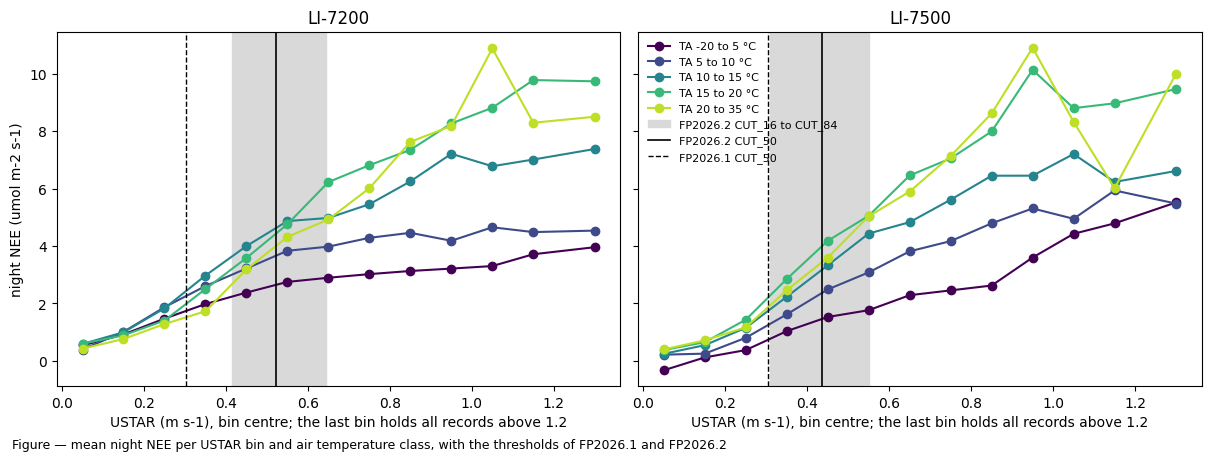

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained', sharey=True)
_mid = 0.5 * (_ubins[:-1] + _ubins[1:])
_mid[-1] = 1.3
_colors = plt.cm.viridis(np.linspace(0, 0.9, len(_tbins) - 1))
for _ax, _a in zip(axes, data):
    _c = curves[_a]
    for _col, _clr in zip(_c.columns, _colors):
        _ax.plot(_mid[:len(_c)], _c[_col].to_numpy(), marker='o', color=_clr, label=f"TA {_col.left:.0f} to {_col.right:.0f} °C")
    _cut = USTAR_THRESHOLDS[_a]
    _ax.axvspan(_cut[0], _cut[2], color='0.85', zorder=0, label='FP2026.2 CUT_16 to CUT_84')
    _ax.axvline(_cut[1], color='k', lw=1.2, label='FP2026.2 CUT_50')
    _ax.axvline(USTAR_THRESHOLDS_FP1[1], color='k', lw=1, ls='--', label='FP2026.1 CUT_50')
    _ax.set_title(ANALYSERS[_a])
    _ax.set_xlabel('USTAR (m s-1), bin centre; the last bin holds all records above 1.2')
axes[0].set_ylabel('night NEE (umol m-2 s-1)')
axes[1].legend(frameon=False, fontsize=8, loc='upper left')
figcap(fig, "mean night NEE per USTAR bin and air temperature class, with the thresholds of FP2026.1 and FP2026.2")
plt.show()

Night `NEE` does not level off at the thresholds. In every temperature class it keeps rising with
`USTAR` up to about 0.9 to 1.0 m s⁻¹, in both analysers, and in the warmest classes beyond. Neither
the thresholds of FP2026.1 nor those of FP2026.2 mark the start of a plateau. Part of the rise may be
real, because wind can draw CO2 out of the soil and the litter. The tower data alone cannot separate
this from flux that is not measured at the tower.

</br>

# 5. Daytime records at low USTAR

REddyProc applies the USTAR filter only at night by default; ONEFlux and this chain apply it by day
too. Daytime records at low `USTAR` would be worth keeping if their `NEE` agreed with that of
well-mixed records under the same conditions. Each daytime record is compared with the mean `NEE`
at `USTAR` above 0.5 m s-1 in its cell: the same month, 50 W m-2 of `SW_IN`, 2 K of `TA` and
quarter of `VPD` (cells with at least 5 such records).

## 📋 Table: daytime NEE at low USTAR against well-mixed records

In [21]:
_parts = {}
for _a, _d in data.items():
    _day = _d[(_d[NIGHTTIME] == 0)].dropna(subset=[NEE, USTAR, VPD, ZL]).copy()
    _vq = pd.qcut(_day[VPD], 4, labels=False)
    _day['cell'] = list(zip((_day[SW_IN] // 50).astype(int), _day.index.month, (_day[TA] // 2).astype(int), _vq))
    _ref = _day[_day[USTAR] > 0.5].groupby('cell')[NEE].agg(['mean', 'size'])
    _day['anom'] = _day[NEE] - _day['cell'].map(_ref['mean'].where(_ref['size'] >= 5))
    _day['group'] = np.where(_day[SW_IN] < 100, 'SW_IN 10-100 (dawn, dusk)',
                             np.where(_day[ZL] < -0.05, 'SW_IN from 100, unstable', 'SW_IN from 100, neutral or stable'))
    _ub = pd.cut(_day[USTAR], [0, 0.1, 0.2, 0.3, 0.4, 0.5, 3])
    _parts[ANALYSERS[_a]] = _day.pivot_table(index=_ub, columns='group', values='anom', aggfunc='mean', observed=True)
day_table = pd.concat(_parts, axis=1)
day_table.index = [f"{i.left:.1f}-{i.right:.1f}" for i in day_table.index]
day_table.index.name = 'USTAR (m s-1)'
day_table.columns = [f"{a}, {g}" for a, g in day_table.columns]
display(styled(day_table, caption="daytime NEE minus the mean NEE at USTAR above 0.5 m s-1 in the same cell "
                                  "(umol m-2 s-1). Positive: less uptake than the well-mixed records; negative: "
                                  "more uptake"))

Table — daytime NEE minus the mean NEE at USTAR above 0.5 m s-1 in the same cell (umol m-2 s-1).
Positive: less uptake than the well-mixed records; negative: more uptake



,"LI-7200, SW_IN 10-100 (dawn, dusk)","LI-7200, SW_IN from 100, neutral or stable","LI-7200, SW_IN from 100, unstable","LI-7500, SW_IN 10-100 (dawn, dusk)","LI-7500, SW_IN from 100, neutral or stable","LI-7500, SW_IN from 100, unstable"
USTAR (m s-1),,,,,,
0.0-0.1,-2.52,4.86,3.60,-2.37,6.31,4.81
0.1-0.2,-2.26,4.11,3.94,-1.79,7.47,4.41
0.2-0.3,-1.80,4.26,3.51,-1.68,5.46,3.66
0.3-0.4,-1.40,3.31,2.15,-1.51,3.91,2.45
0.4-0.5,-0.75,1.66,1.09,-0.72,2.18,1.52
0.5-3.0,-0.00,0.42,-0.15,-0.00,0.23,-0.08


Daytime records at low `USTAR` differ from the well-mixed records under the same conditions. In sun
(`SW_IN` from 100 W m⁻²) they show less uptake, by about 2 to 8 µmol m⁻² s⁻¹ below 0.4 m s⁻¹. At dawn
and dusk they show more uptake, by about 1.4 to 2.6 µmol m⁻² s⁻¹, which is the night-time bias
carried into the twilight. The filter therefore applies by day as well, as in ONEFlux.

</br>

# 6. Records kept and night-time respiration

A higher threshold removes more records. Their number decides how well gap-filling and the
night-time partitioning are constrained.

## 📋 Table: records kept per threshold

In [22]:
if CHAIN_AVAILABLE:
    _rows = {}
    reco = {}
    for _a, _d in data.items():
        _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
        _night = _d[NIGHTTIME] == 1
        _yr = _d.index.year
        _ok = _d[NEE].notna()
        _thr = {**COMPARE, 'FP2026.2 CUT_16': USTAR_THRESHOLDS[_a][0], 'FP2026.2 CUT_50': USTAR_THRESHOLDS[_a][1],
                'FP2026.2 CUT_84': USTAR_THRESHOLDS[_a][2]}
        _e0 = _d.groupby(_yr)['E0_NT_OF_CUT_50'].median()
        for _lab, _t in sorted(_thr.items(), key=lambda kv: kv[1]):
            _kept = _ok & (_d[USTAR] >= _t)
            _r = reco_estimate(_d, _d[NEE].where(_kept & (_d[SW_IN] < NIGHT_SW_IN)), _e0)
            reco[(_a, _lab)] = _r.groupby(_yr).sum(min_count=1) * GC
            _rows[(ANALYSERS[_a], f"{_lab} ({_t:.2f})")] = {
                'day records per year': _kept[~_night].groupby(_yr[~_night]).sum().mean(),
                'night records per year': _kept[_night].groupby(_yr[_night]).sum().mean(),
                'night measured (%)': _kept[_night].groupby(_yr[_night]).mean().mean() * 100,
                'night measured, lowest year (%)': _kept[_night].groupby(_yr[_night]).mean().min() * 100}
        _rows[(ANALYSERS[_a], 'no USTAR filter')] = {
            'day records per year': _ok[~_night].groupby(_yr[~_night]).sum().mean(),
            'night records per year': _ok[_night].groupby(_yr[_night]).sum().mean(),
            'night measured (%)': _ok[_night].groupby(_yr[_night]).mean().mean() * 100,
            'night measured, lowest year (%)': _ok[_night].groupby(_yr[_night]).mean().min() * 100}
    kept_table = pd.DataFrame(_rows).T
    display(styled(kept_table, caption="NEE records per complete year after Level 3.2 that pass the USTAR filter at each "
                                       "threshold, by day and by night (night as flagged by the chain), and the share of "
                                       "the night half-hours they cover", fmt={'day records per year': "{:.0f}",
                                       'night records per year': "{:.0f}", 'night measured (%)': "{:.1f}",
                                       'night measured, lowest year (%)': "{:.1f}"}, cmap=None))
else:
    print("Skipped: needs the results of the full chain (05 outputs).")

Table — NEE records per complete year after Level 3.2 that pass the USTAR filter at each threshold,
by day and by night (night as flagged by the chain), and the share of the night half-hours they
cover



## 📋 Table: night-time respiration per threshold

In [23]:
if CHAIN_AVAILABLE:
    _rows = {}
    for _a, _d in data.items():
        _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
        _chain = _d['RECO_NT_OF_CUT_50'].groupby(_d.index.year).sum(min_count=1) * GC
        _base = reco[(_a, 'FP2026.1 CUT_50')]
        _years = _chain.dropna().index
        _rows[(ANALYSERS[_a], f'chain, {chain_thresholds[_a]} CUT_50')] = {'RECO (gC m-2 per year)': _chain[_years].mean(), 'against FP2026.1 CUT_50 (%)': np.nan}
        for (_aa, _lab), _r in reco.items():
            if _aa != _a:
                continue
            _rows[(ANALYSERS[_a], f"estimate, {_lab}")] = {'RECO (gC m-2 per year)': _r[_years].mean(),
                                                           'against FP2026.1 CUT_50 (%)': (_r[_years].mean() / _base[_years].mean() - 1) * 100}
    reco_table = pd.DataFrame(_rows).T
    display(styled(reco_table, caption="mean annual night-time respiration: the chain's RECO_NT at its CUT_50 "
                                       "threshold, and a simple estimate for each threshold (reference respiration per "
                                       "day from the measured nights, Lloyd-Taylor with the chain's E0 of the year). The "
                                       "estimate at the FP2026.1 threshold checks the method against the chain; the "
                                       "change is relative to that estimate. E0 is held fixed, so only the level changes",
                   fmt={'RECO (gC m-2 per year)': "{:.0f}", 'against FP2026.1 CUT_50 (%)': "{:+.0f}"}, cmap=None))
else:
    print("Skipped: needs the results of the full chain (05 outputs).")

Table — mean annual night-time respiration: the chain's RECO_NT at its CUT_50 threshold, and a
simple estimate for each threshold (reference respiration per day from the measured nights, Lloyd-
Taylor with the chain's E0 of the year). The estimate at the FP2026.1 threshold checks the method
against the chain; the change is relative to that estimate. E0 is held fixed, so only the level
changes



Every increase of the threshold costs measured records. At the FP2026.2 median thresholds about 20 %
of the night half-hours stay measured, against 28 to 37 % at the FP2026.1 threshold, and about 15 % in
the poorest year. By day the loss is similar. The night-time respiration estimated from the measured
nights rises with the threshold, by 20 to 26 % at the FP2026.2 median thresholds.

</br>

# 7. Comparison with FLUXNET

FLUXNET (ONEFlux v1.3) detects thresholds per year with the moving point and the change point
methods pooled, and selects one of 40 threshold percentiles as the reference, once for a constant
threshold over all years (`CUT_REF`) and once per year (`VUT_REF`). Until 2015 it uses the LI-7500
with its own self-heating correction, from 2016 the LI-7200. The full comparison of the LI-7500
years is in [`FLUX_NEE_IRGA75_COMPARISONS`](../90_OVERVIEW/FLUX_NEE_IRGA75_COMPARISONS.ipynb).

The annual sums of this product come from the 05 outputs, at the thresholds that run applied
(table under Integrity checks).

In [24]:
_bif = pd.read_csv(FLUXNET_DIR / FLUXNET_BIF)
_ref = _bif[_bif['VARIABLE_GROUP'] == 'GRP_FLUX_REF'].pivot_table(index='GROUP_ID', columns='VARIABLE', values='DATAVALUE', aggfunc='first')
_ref = _ref[(_ref['REF_VARIABLE'] == 'NEE') & (_ref['REF_TIME_RESOLUTION'] == 'HH')]
FLX_CUT_REF = float(_ref.loc[_ref['REF_VERSION'] == 'CUT', 'REF_USTAR_THRESHOLD'].iloc[0])
_v = _ref[_ref['REF_VERSION'] == 'VUT']
FLX_VUT_REF = _v.assign(year=_v['REF_YEAR'].astype(int)).groupby('year')['REF_USTAR_THRESHOLD'].first().astype(float)
_yy = pd.read_csv(FLUXNET_DIR / FLUXNET_YY, na_values=FLX_MISSING).set_index('TIMESTAMP')
_hh = pd.read_csv(FLUXNET_DIR / FLUXNET_HH, na_values=FLX_MISSING,
                  usecols=['TIMESTAMP_START', 'NIGHT', 'NEE_CUT_REF', 'NEE_CUT_REF_QC', 'NEE_VUT_REF', 'NEE_VUT_REF_QC'])
_hh.index = pd.to_datetime(_hh.pop('TIMESTAMP_START').astype(str), format='%Y%m%d%H%M') + pd.Timedelta('15min')
flx_hh = _hh
# this product: LI-7500 to 2015, LI-7200 from 2016, at the thresholds of the current chain run
prod_hh = pd.concat([data['IRGA75'].loc[:'2015'], data['IRGA72'].loc['2016':'2024']])
print(f"FLUXNET CUT_REF threshold for half-hourly NEE: {FLX_CUT_REF:.3f} m s-1")

FLUXNET CUT_REF threshold for half-hourly NEE: 0.430 m s-1


## 📋 Table: thresholds of FLUXNET and of this product per year

In [25]:
_mp_vut = pd.concat([detections[('IRGA75', 'oneflux_mp')].get_vut_thresholds()['p50'].loc[:2015],
                     detections[('IRGA72', 'oneflux_mp')].get_vut_thresholds()['p50'].loc[2016:2024]])
flx_thr = pd.DataFrame({'FLUXNET VUT_REF': FLX_VUT_REF, 'FLUXNET CUT_REF': FLX_CUT_REF,
                        'this product, moving point VUT (median)': _mp_vut})
flx_thr['this product, FP2026.2 CUT_50'] = [USTAR_THRESHOLDS['IRGA75'][1] if y <= 2015 else USTAR_THRESHOLDS['IRGA72'][1]
                                           for y in flx_thr.index]
flx_thr['this product, FP2026.1 CUT_50'] = USTAR_THRESHOLDS_FP1[1]
flx_thr.index.name = 'year'
display(styled(flx_thr, caption="USTAR thresholds (m s-1) for half-hourly NEE: the reference thresholds FLUXNET "
                                "selected, per year (VUT_REF) and constant (CUT_REF), and those of this product. "
                                "The analyser is the LI-7500 to 2015 and the LI-7200 from 2016 in both", cmap=None))

Table — USTAR thresholds (m s-1) for half-hourly NEE: the reference thresholds FLUXNET selected, per
year (VUT_REF) and constant (CUT_REF), and those of this product. The analyser is the LI-7500 to
2015 and the LI-7200 from 2016 in both



,FLUXNET VUT_REF,FLUXNET CUT_REF,"this product, moving point VUT (median)","this product, FP2026.2 CUT_50","this product, FP2026.1 CUT_50"
year,,,,,
2004,0.28,0.43,0.44,0.44,0.30
2005,0.26,0.43,0.42,0.44,0.30
2006,0.32,0.43,0.44,0.44,0.30
2007,0.30,0.43,0.49,0.44,0.30
2008,0.29,0.43,0.49,0.44,0.30
2009,0.27,0.43,0.44,0.44,0.30
2010,0.23,0.43,0.41,0.44,0.30
2011,0.24,0.43,0.40,0.44,0.30
2012,0.26,0.43,0.42,0.44,0.30


## 📋 Table: annual NEE and night records of FLUXNET and of this product

In [26]:
if CHAIN_AVAILABLE:
    _py, _pn = prod_hh.index.year, prod_hh[NIGHTTIME] == 1
    _pm = prod_hh['FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED'] == 0
    _fy, _fn = flx_hh.index.year, flx_hh['NIGHT'] == 1
    _fm = flx_hh['NEE_VUT_REF_QC'] == 0
    flx_ann = pd.DataFrame({
        'FLUXNET NEE_CUT_REF': _yy['NEE_CUT_REF'], 'FLUXNET NEE_VUT_REF': _yy['NEE_VUT_REF'],
        'this product NEE (CUT_50)': prod_hh['NEE_L3.1_L3.3_CUT_50_QCF_gfXG'].groupby(_py).sum() * GC,
        'FLUXNET VUT_REF night sum': flx_hh.loc[_fn, 'NEE_VUT_REF'].groupby(_fy[_fn]).sum() * GC,
        'this product night sum': prod_hh.loc[_pn, 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG'].groupby(_py[_pn]).sum() * GC,
        'FLUXNET VUT_REF night measured (%)': _fm[_fn].groupby(_fy[_fn]).mean() * 100,
        'this product night measured (%)': _pm[_pn].groupby(_py[_pn]).mean() * 100,
        'FLUXNET VUT_REF mean measured night NEE': flx_hh.loc[_fn & _fm, 'NEE_VUT_REF'].groupby(_fy[_fn & _fm]).mean(),
        'this product mean measured night NEE': prod_hh.loc[_pn & _pm, 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG'].groupby(_py[_pn & _pm]).mean(),
    }).loc[2005:2024]
    flx_ann.index.name = 'year'
    _sums = [c for c in flx_ann.columns if 'NEE_' in c or 'NEE (' in c or 'sum' in c]
    display(styled(flx_ann, caption="annual NEE in gC m-2 (FLUXNET CUT_REF and VUT_REF from its yearly file, this "
                                    "product at the thresholds of its current chain run), the night sums, the share "
                                    "of night half-hours measured, and the mean measured night NEE in umol m-2 s-1. "
                                    "Each product uses its own night flag. 2004 is left out: FLUXNET starts in March",
                   fmt={c: ("{:.0f}" if c in _sums else ("{:.1f}" if '%' in c else "{:.2f}")) for c in flx_ann.columns}, cmap=None))
else:
    print("Skipped: needs the results of the full chain (05 outputs).")

Table — annual NEE in gC m-2 (FLUXNET CUT_REF and VUT_REF from its yearly file, this product at the
thresholds of its current chain run), the night sums, the share of night half-hours measured, and
the mean measured night NEE in umol m-2 s-1. Each product uses its own night flag. 2004 is left out:
FLUXNET starts in March



,FLUXNET NEE_CUT_REF,FLUXNET NEE_VUT_REF,this product NEE (CUT_50),FLUXNET VUT_REF night sum,this product night sum,FLUXNET VUT_REF night measured (%),this product night measured (%),FLUXNET VUT_REF mean measured night NEE,this product mean measured night NEE
year,,,,,,,,,
2005,60,-158,92,398,651,23.6,17.5,2.53,3.66
2006,-49,-124,140,355,706,22.3,20.0,2.52,4.34
2007,-251,-352,-112,425,697,25.4,23.8,2.78,4.05
2008,-208,-201,12,441,705,26.0,23.1,2.87,4.32
2009,-227,-270,4,314,672,24.4,18.4,1.82,3.62
2010,-448,-441,-97,277,612,25.9,19.4,1.99,3.88
2011,-493,-517,-175,443,776,26.2,20.8,2.85,4.60
2012,-492,-680,-319,273,618,21.7,16.9,2.29,3.91
2013,-521,-545,-290,306,587,23.5,20.6,2.06,3.85


## 📋 Table: mean annual NEE per period

In [27]:
if CHAIN_AVAILABLE:
    _periods = {'2005-2006': (2005, 2006), '2007-2015': (2007, 2015), '2016-2017': (2016, 2017), '2018-2024': (2018, 2024),
                '2005-2024': (2005, 2024)}
    flx_period = pd.DataFrame({k: flx_ann.loc[a:b, ['FLUXNET NEE_CUT_REF', 'FLUXNET NEE_VUT_REF', 'this product NEE (CUT_50)',
                                                    'FLUXNET VUT_REF night sum', 'this product night sum']].mean()
                               for k, (a, b) in _periods.items()}).T
    display(styled(flx_period, caption="mean annual NEE and night sum (gC m-2) per period. Negative NEE is net uptake",
                   fmt="{:.0f}", cmap=None))
else:
    print("Skipped: needs the results of the full chain (05 outputs).")

Table — mean annual NEE and night sum (gC m-2) per period. Negative NEE is net uptake



,FLUXNET NEE_CUT_REF,FLUXNET NEE_VUT_REF,this product NEE (CUT_50),FLUXNET VUT_REF night sum,this product night sum
2005-2006,5,-141,116,376,678
2007-2015,-381,-437,-138,346,679
2016-2017,109,104,138,868,894
2018-2024,-48,3,-32,830,844
2005-2024,-177,-199,-48,570,758


## 📋 Table: half-hours measured in both products

In [28]:
if CHAIN_AVAILABLE:
    _j = flx_hh.join(prod_hh[['NEE_L3.1_L3.3_CUT_50_QCF_gfXG', 'FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED']], how='inner')
    _j = _j[(_j['NEE_VUT_REF_QC'] == 0) & (_j['FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED'] == 0)]
    _diff = _j['NEE_L3.1_L3.3_CUT_50_QCF_gfXG'] - _j['NEE_VUT_REF']
    _period = np.where(_j.index.year <= 2015, '2004-2015 (LI-7500)', '2016-2024 (LI-7200)')
    _tod = np.where(_j['NIGHT'] == 1, 'night', 'day')
    _g = _diff.groupby([_period, _tod])
    flx_common = pd.DataFrame({'half-hours': _g.size(), 'this product minus FLUXNET, mean': _g.mean(),
                               'median': _g.median()})
    display(styled(flx_common, caption="NEE of this product minus FLUXNET VUT_REF (umol m-2 s-1) on the half-hours "
                                       "both measured", fmt={'half-hours': "{:.0f}"}, cmap=None))
else:
    print("Skipped: needs the results of the full chain (05 outputs).")

Table — NEE of this product minus FLUXNET VUT_REF (umol m-2 s-1) on the half-hours both measured



Over 2005-2024 FLUXNET shows more net uptake than this product (-177 and -199 against -48 gC m⁻²
per year). The difference lies in the LI-7500 years.

- **2005-2015, LI-7500: FLUXNET shows more uptake**, in 2007-2015 by about 240 (`CUT_REF`) and 300
  gC m⁻² per year (`VUT_REF`). The difference lies at night. FLUXNET's night sums are about 330 gC m⁻²
  lower, and on the half-hours both measured its night `NEE` is lower by 0.66 µmol m⁻² s⁻¹ on average;
  by day the two agree within 0.2. Its `VUT_REF` thresholds of these years (0.23 to 0.35 m s⁻¹) lie
  below the FP2026.2 threshold of the LI-7500 (0.44 m s⁻¹), which adds to the difference. The
  difference on the half-hours both measured does not depend on the threshold; its cause is the
  self-heating correction of the LI-7500
  ([`FLUX_NEE_IRGA75_COMPARISONS`](../90_OVERVIEW/FLUX_NEE_IRGA75_COMPARISONS.ipynb)).
- **2016-2024, LI-7200: the two agree.** In 2018-2024 FLUXNET's mean annual `NEE` is +3 (`VUT_REF`)
  and -48 gC m⁻² (`CUT_REF`), against -32 here; in 2016-2017 it is 104 and 109, against 138 here. The
  night sums differ by less than 30 gC m⁻² per year, and on the half-hours both measured the two
  agree. The thresholds are similar: 0.46 to 0.60 m s⁻¹ (`VUT_REF`) against 0.52 m s⁻¹ here.
  FLUXNET keeps fewer night half-hours as measured (10 to 19 %, against 15 to 25 % here).
- **Within FLUXNET**, `VUT_REF` shows more uptake than `CUT_REF` where its yearly thresholds lie below
  the constant one (to 2015) and less where they lie above it (from 2016): the same dependence on the
  threshold as in sections 4 and 6.

</br>

# 8. Pooling years and seasons

ONEFlux detects the threshold once per calendar year and pools the bootstrap draws afterwards: the
VUT of a year from the year and its two neighbours, the CUT from all years. The detection itself
sees one year of data. Here the data are pooled before the detection, in two ways:

- **several years:** the moving point method runs on the data of 3 or 5 years centred on the year.
  Each season then holds the same months of all these years, so each temperature and `USTAR` class
  has more records;
- **all years, other seasons:** the moving point method runs on all years at once, with calendar
  quarters, with a leaf-off and a leaf-on season, or with one season. This gives one threshold per
  season.

Each detection has 100 bootstrap draws. The annual threshold is the highest season threshold, as in
ONEFlux.

In [29]:
from joblib import Parallel, delayed


def mp_pooled(frame, seasons):
    """Moving point detection on `frame` with `seasons`: main-run season thresholds and bootstrap
    statistics per season and for the annual (highest season) threshold."""
    try:
        _det = UstarMovingPointDetection(frame, season_groups=seasons, bootstrapping_times=POOL_DRAWS,
                                         random_state=DETECTION['random_state'], verbose=0, **DET_COLS)
        _main = _det.detect()['threshold']
        return _main, _det.bootstrap()
    except ValueError:
        return None, None


_tasks = []
for _a, _d in data.items():
    _y0, _y1 = COMPLETE_YEARS[_a]
    for _y in range(_y0, _y1 + 1):
        for _n in POOL_YEARS:
            _h = _n // 2
            _tasks.append(((_a, f'{_n} year' + ('s' if _n > 1 else ''), _y),
                           _d.loc[str(max(_y0, _y - _h)):str(min(_y1, _y + _h))], SEASONS['quarters']))
    for _lab, _s in SEASONS.items():
        _tasks.append(((_a, f'all years, {_lab}', 0), _d.loc[str(_y0):str(_y1)], _s))
_t = time.time()
_res = Parallel(n_jobs=-1)(delayed(mp_pooled)(_f, _s) for _, _f, _s in _tasks)
pooled = {_k: _r for (_k, _, _), _r in zip(_tasks, _res)}
print(f"{len(_tasks)} detections in {time.time() - _t:.0f} s")

78 detections in 6 s


## 📋 Table: annual threshold per year, one year and pooled years

In [30]:
_rows = {}
for (_a, _var, _y), (_main, _boot) in pooled.items():
    if _y and _boot is not None:
        _rows.setdefault((ANALYSERS[_a], _y), {})[f'{_var} pooled' if _var != '1 year' else '1 year'] = _boot.loc['Annual', 'p50']
for _a in data:
    for _y, _v in detections[(_a, 'oneflux_mp')].get_vut_thresholds()['p50'].items():
        if (ANALYSERS[_a], _y) in _rows:
            _rows[(ANALYSERS[_a], _y)]['VUT (ONEFlux)'] = _v
pool_table = pd.DataFrame(_rows).T
display(styled(pool_table, caption="median of the bootstrap draws of the annual USTAR threshold (m s-1), moving point "
                                    "method with calendar quarters, on the data of the year alone and of 3 and 5 years "
                                    "centred on it (shorter at the ends of the record), and the VUT of ONEFlux, which "
                                    "pools the draws of single years", cmap=None))

Table — median of the bootstrap draws of the annual USTAR threshold (m s-1), moving point method
with calendar quarters, on the data of the year alone and of 3 and 5 years centred on it (shorter at
the ends of the record), and the VUT of ONEFlux, which pools the draws of single years



## 📋 Table: change from year to year against the bootstrap spread

In [31]:
_rows = {}
for _a in data:
    for _var in ('1 year', '3 years', '5 years'):
        _b = [r[1] for (a, v, y), r in pooled.items() if a == _a and v == _var and y and r[1] is not None]
        _med = np.array([b.loc['Annual', 'p50'] for b in _b])
        _sd = np.array([b.loc['Annual', 'std'] for b in _b])
        _rows[(ANALYSERS[_a], _var)] = {'lowest year': _med.min(), 'highest year': _med.max(),
                                        'sd between years': _med.std(ddof=1), 'bootstrap sd within a year': _sd.mean(),
                                        'ratio': _med.std(ddof=1) / _sd.mean()}
spread_table = pd.DataFrame(_rows).T
display(styled(spread_table, caption="spread of the annual thresholds (m s-1) between years, against the mean "
                                      "standard deviation of the bootstrap draws within a year. A ratio below 1 means "
                                      "the years differ by no more than the sampling noise of one year", cmap=None))

Table — spread of the annual thresholds (m s-1) between years, against the mean standard deviation
of the bootstrap draws within a year. A ratio below 1 means the years differ by no more than the
sampling noise of one year



## 📊 Plot: annual threshold per year with the data of one, three and five years

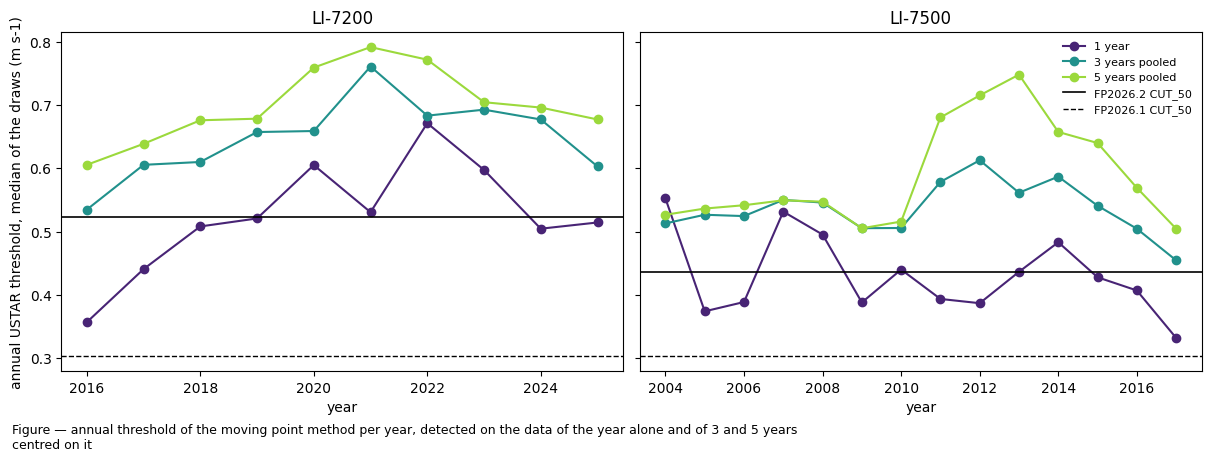

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained', sharey=True)
for _ax, _a in zip(axes, data):
    _t = pool_table.loc[ANALYSERS[_a]]
    for _col, _clr in zip(['1 year', '3 years pooled', '5 years pooled'], plt.cm.viridis([0.1, 0.5, 0.85])):
        _ax.plot(_t.index, _t[_col], marker='o', color=_clr, label=_col)
    _ax.axhline(USTAR_THRESHOLDS[_a][1], color='k', lw=1.2, label='FP2026.2 CUT_50')
    _ax.axhline(USTAR_THRESHOLDS_FP1[1], color='k', lw=1, ls='--', label='FP2026.1 CUT_50')
    _ax.set_title(ANALYSERS[_a])
    _ax.set_xlabel('year')
axes[0].set_ylabel('annual USTAR threshold, median of the draws (m s-1)')
axes[1].legend(frameon=False, fontsize=8)
figcap(fig, "annual threshold of the moving point method per year, detected on the data of the year alone and of "
            "3 and 5 years centred on it")
plt.show()

## 📋 Table: thresholds per season with all years pooled

In [33]:
_rows = {}
for (_a, _var, _y), (_main, _boot) in pooled.items():
    if _y:
        continue
    _lab = _var.replace('all years, ', '')
    for _i, _months in enumerate(SEASONS[_lab]):
        _s = f'Season {_i + 1}'
        _rows[(ANALYSERS[_a], _lab, f"{_s}: months {','.join(map(str, _months))}")] = {
            'main run': _main[_s] if _main is not None else np.nan,
            'draws, median': _boot.loc[_s, 'p50'] if _boot is not None else np.nan,
            'draws, p05': _boot.loc[_s, 'p05'] if _boot is not None else np.nan,
            'draws, p95': _boot.loc[_s, 'p95'] if _boot is not None else np.nan}
    if _boot is not None:
        _rows[(ANALYSERS[_a], _lab, 'annual, highest season')] = {
            'main run': np.nanmax(_main.to_numpy()) if _main.notna().any() else np.nan,
            'draws, median': _boot.loc['Annual', 'p50'], 'draws, p05': _boot.loc['Annual', 'p05'],
            'draws, p95': _boot.loc['Annual', 'p95']}
season_table = pd.DataFrame(_rows).T
display(styled(season_table, caption="USTAR thresholds (m s-1) of the moving point method on all complete years at "
                                      "once, per season, from the main run (empty where it finds no plateau) and from "
                                      "the draws that found one", cmap=None))

Table — USTAR thresholds (m s-1) of the moving point method on all complete years at once, per
season, from the main run (empty where it finds no plateau) and from the draws that found one



## 📋 Table: records kept and night-time respiration per pooling

In [34]:
if CHAIN_AVAILABLE:
    _rows = {}
    for _a, _d in data.items():
        _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
        _yr, _mo = _d.index.year, _d.index.month
        _night = _d[NIGHTTIME] == 1
        _ok = _d[NEE].notna()
        _e0 = _d.groupby(_yr)['E0_NT_OF_CUT_50'].median()
        _thr = {'FP2026.1 CUT_50': pd.Series(USTAR_THRESHOLDS_FP1[1], index=_d.index),
                'FP2026.2 CUT_50': pd.Series(USTAR_THRESHOLDS[_a][1], index=_d.index)}
        for _var in ('1 year', '3 years', '5 years'):
            _per_year = {y: r[1].loc['Annual', 'p50'] for (a, v, y), r in pooled.items() if a == _a and v == _var and y}
            _thr[f'{_var}, per year'] = pd.Series(_yr.map(_per_year), index=_d.index)
        for _lab, _s in SEASONS.items():
            _boot = pooled[(_a, f'all years, {_lab}', 0)][1]
            _by_month = {m: _boot.loc[f'Season {i + 1}', 'p50'] for i, g in enumerate(_s) for m in g}
            _thr[f'all years, {_lab}, per season'] = pd.Series(_mo.map(_by_month), index=_d.index)
        _base = None
        for _lab, _t in _thr.items():
            _kept = _ok & (_d[USTAR] >= _t)
            _r = (reco_estimate(_d, _d[NEE].where(_kept & (_d[SW_IN] < NIGHT_SW_IN)), _e0).groupby(_yr).sum(min_count=1) * GC).mean()
            _base = _r if _lab == 'FP2026.2 CUT_50' else _base
            _rows[(ANALYSERS[_a], _lab)] = {'mean threshold': _t[_night].mean(),
                                            'night measured (%)': _kept[_night].groupby(_yr[_night]).mean().mean() * 100,
                                            'RECO (gC m-2 per year)': _r}
        for _k in [k for k in _rows if k[0] == ANALYSERS[_a]]:
            _rows[_k]['against FP2026.2 CUT_50 (%)'] = (_rows[_k]['RECO (gC m-2 per year)'] / _base - 1) * 100
    pool_effect = pd.DataFrame(_rows).T
    display(styled(pool_effect, caption="mean threshold at night (m s-1), share of the night half-hours that stay measured, "
                                         "and the night-time respiration estimated as in section 6, for each way of pooling. "
                                         "Per-season thresholds apply to the months of their season",
                   fmt={'mean threshold': "{:.2f}", 'night measured (%)': "{:.1f}", 'RECO (gC m-2 per year)': "{:.0f}",
                        'against FP2026.2 CUT_50 (%)': "{:+.0f}"}, cmap=None))
else:
    print("Skipped: needs the results of the full chain (05 outputs).")

Table — mean threshold at night (m s-1), share of the night half-hours that stay measured, and the
night-time respiration estimated as in section 6, for each way of pooling. Per-season thresholds
apply to the months of their season



The thresholds of single years differ by no more than the bootstrap spread within one year, for both
analysers. The threshold therefore stays constant, one value per analyser; a VUT would add scatter
from year to year without a detectable change behind it.

Pooling the data of more years raises the threshold. With all years pooled, the main run finds no
plateau from April to September, and only some of the draws find one: with enough records per class
the plateau test does not pass in summer. The thresholds of single years are low partly because the
class means of one year are noisy enough to pass the plateau test early, as in the synthetic test of
section 3. A threshold from pooled years is therefore not better defined, only higher, and it moves
further as more data are added.

Pooling across seasons (leaf-off and leaf-on, or one season) puts records of different seasons into
the same temperature class. For the LI-7200 this gives 0.73 to 0.79 m s⁻¹. For the LI-7500 the main
run with one season finds no threshold, and the draws that find one give 0.13 m s⁻¹, below the
threshold of every single year. The thresholds per quarter differ between the two analysers and do
not show a common seasonal pattern. Neither gives a usable seasonal threshold.

</br>

# 9. Night NEE against the respiration of the daytime partitioning

The daytime partitioning of the chain (Lasslop et al. 2010, `RECO_DT_OF_CUT_50`) estimates respiration
from the daytime light response, when turbulence is strong. It gives a reference for night `NEE` from
daytime records, but it is not independent of the night-time `USTAR` filter: its temperature
sensitivity comes from the night records that pass it. If night `NEE` were only too low at weak turbulence, it would rise towards this
reference and stay there.

`RECO_DT_OF_CUT_50` comes from the 05 outputs, with the thresholds that run applied (table under
Integrity checks).

## 📋 Table: night NEE against RECO_DT by USTAR

In [35]:
if CHAIN_AVAILABLE:
    _ubins = [0, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1.0, 1.2, 3]
    _rows = {}
    dt_ratio = {}
    for _a, _d in data.items():
        _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
        _n = _d[(_d[SW_IN] < NIGHT_SW_IN)].dropna(subset=[NEE, RECO_DT, USTAR])
        _season = np.where(_n.index.month.isin(LEAF_ON), 'May-Oct', 'Nov-Apr')
        _g = _n.groupby([_season, pd.cut(_n[USTAR], _ubins)], observed=True)
        _t = pd.DataFrame({'n': _g.size(), 'NEE': _g[NEE].mean(), 'RECO_DT': _g[RECO_DT].mean()})
        _t['NEE / RECO_DT'] = _t['NEE'] / _t['RECO_DT']
        dt_ratio[_a] = _t
        for (_s, _b), _r in _t.iterrows():
            _rows[(ANALYSERS[_a], _s, f"{_b.left:.1f}-{_b.right:.1f}")] = _r
    dt_table = pd.DataFrame(_rows).T
    display(styled(dt_table, caption="mean night NEE and mean RECO_DT of the same half-hours (umol m-2 s-1) per USTAR "
                                      "class, before the USTAR filter, and their ratio, for May to October and November "
                                      "to April", fmt={'n': "{:.0f}"}, cmap=None))
else:
    print("Skipped: needs the results of the full chain (05 outputs).")

Table — mean night NEE and mean RECO_DT of the same half-hours (umol m-2 s-1) per USTAR class,
before the USTAR filter, and their ratio, for May to October and November to April



## 📊 Plot: night NEE relative to RECO_DT by USTAR

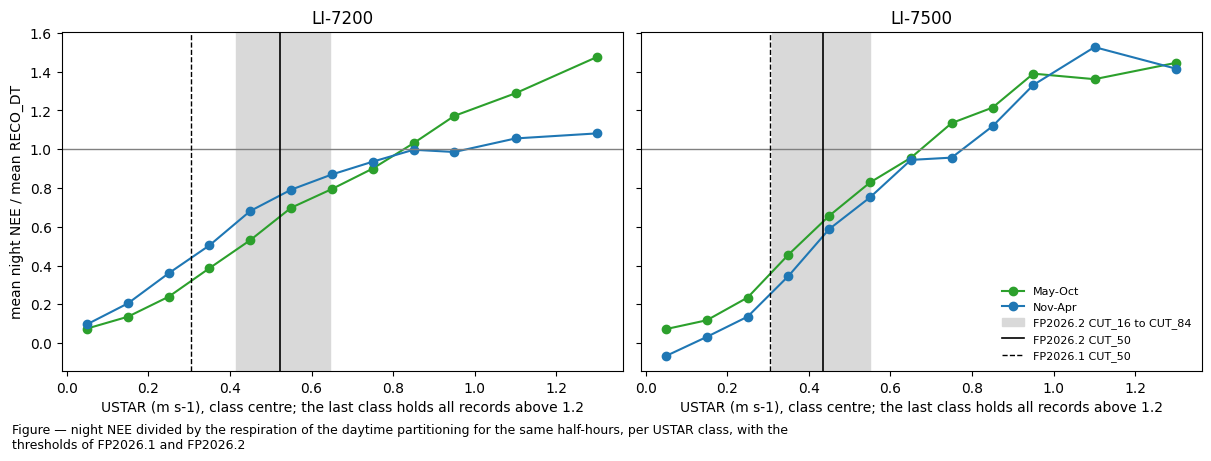

In [36]:
if CHAIN_AVAILABLE:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained', sharey=True)
    for _ax, _a in zip(axes, data):
        for _s, _clr in zip(('May-Oct', 'Nov-Apr'), ('tab:green', 'tab:blue')):
            _t = dt_ratio[_a].loc[_s]
            _mid = [min(b.mid, 1.3) for b in _t.index]
            _ax.plot(_mid, _t['NEE / RECO_DT'], marker='o', color=_clr, label=_s)
        _ax.axhline(1, color='0.5', lw=1)
        _cut = USTAR_THRESHOLDS[_a]
        _ax.axvspan(_cut[0], _cut[2], color='0.85', zorder=0, label='FP2026.2 CUT_16 to CUT_84')
        _ax.axvline(_cut[1], color='k', lw=1.2, label='FP2026.2 CUT_50')
        _ax.axvline(USTAR_THRESHOLDS_FP1[1], color='k', lw=1, ls='--', label='FP2026.1 CUT_50')
        _ax.set_title(ANALYSERS[_a])
        _ax.set_xlabel('USTAR (m s-1), class centre; the last class holds all records above 1.2')
    axes[0].set_ylabel('mean night NEE / mean RECO_DT')
    axes[1].legend(frameon=False, fontsize=8)
    figcap(fig, "night NEE divided by the respiration of the daytime partitioning for the same half-hours, per USTAR "
                "class, with the thresholds of FP2026.1 and FP2026.2")
    plt.show()
else:
    print("Skipped: needs the results of the full chain (05 outputs).")

## 📋 Table: kept nights against RECO_DT per threshold

In [37]:
if CHAIN_AVAILABLE:
    _rows = {}
    for _a, _d in data.items():
        _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
        _n = _d[(_d[SW_IN] < NIGHT_SW_IN)].dropna(subset=[NEE, RECO_DT, USTAR])
        _thr = {'FP2026.1 CUT_50': USTAR_THRESHOLDS_FP1[1], 'FP2026.2 CUT_16': USTAR_THRESHOLDS[_a][0],
                'FP2026.2 CUT_50': USTAR_THRESHOLDS[_a][1], 'FP2026.2 CUT_84': USTAR_THRESHOLDS[_a][2]}
        _grid = np.round(np.arange(0.20, 1.001, 0.01), 2)
        _ratio = pd.Series([_n.loc[_n[USTAR] >= u, NEE].mean() / _n.loc[_n[USTAR] >= u, RECO_DT].mean() for u in _grid],
                           index=_grid)
        _equal = float(_ratio.index[np.argmax(_ratio.to_numpy() >= 1)]) if (_ratio >= 1).any() else np.nan
        for _lab, _t in {**_thr, 'kept nights equal RECO_DT': _equal}.items():
            _k = _n[_n[USTAR] >= _t]
            _rows[(ANALYSERS[_a], _lab)] = {'threshold': _t, 'night records kept (%)': len(_k) / len(_n) * 100,
                                            'mean NEE / mean RECO_DT': _k[NEE].mean() / _k[RECO_DT].mean()}
    dt_thr_table = pd.DataFrame(_rows).T
    display(styled(dt_thr_table, caption="mean night NEE of the records at or above each threshold, divided by the mean "
                                          "RECO_DT of the same records; the last row of each analyser is the lowest "
                                          "threshold at which the two are equal",
                   fmt={'threshold': "{:.2f}", 'night records kept (%)': "{:.1f}", 'mean NEE / mean RECO_DT': "{:.2f}"},
                   cmap=None))
else:
    print("Skipped: needs the results of the full chain (05 outputs).")

Table — mean night NEE of the records at or above each threshold, divided by the mean RECO_DT of the
same records; the last row of each analyser is the lowest threshold at which the two are equal



Night `NEE` rises to the respiration of the daytime partitioning at a `USTAR` of about 0.7 to
0.9 m s⁻¹ and does not stop there: above it, it exceeds `RECO_DT`, by up to about 50 % in both
analysers. At the FP2026.2 median thresholds the nights that are kept lie 7 % (LI-7200) and 2 %
(LI-7500) below `RECO_DT` on average, and at the FP2026.1 threshold 27 % and 19 % below. The two
agree at 0.64 and 0.46 m s⁻¹, close to `CUT_84` of the LI-7200 and to `CUT_50` of the LI-7500.

`RECO_DT` is not independent of the threshold. Its temperature sensitivity comes from the night
records that pass the `USTAR` filter, so it rises when the chain applies a higher threshold. With the
FP2026.1 thresholds in the chain, the kept nights matched `RECO_DT` near `CUT_16`; with those of
FP2026.2 they match it near `CUT_84` (LI-7200) and `CUT_50` (LI-7500). The comparison therefore does
not constrain the threshold. It also does not decide which estimate is right: `RECO_DT` depends on the
light-response model as well, and night `NEE` at high `USTAR` may include CO2 released from the canopy
air (section 10).

</br>

# 10. Night NEE at high USTAR after calm hours

When the wind rises after calm hours, CO2 that has collected in the canopy air is flushed out and
passes the sensor. The storage term accounts for this only as far as the concentration at the
measurement height shows it. If flushing contributes to the high night `NEE` at high `USTAR`, the
excess over `RECO_DT` should be larger after calm hours than after windy ones.

## 📋 Table: night NEE at high USTAR by the USTAR of the previous hours

In [38]:
if CHAIN_AVAILABLE:
    _rows = {}
    for _a, _d in data.items():
        _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
        _prev = _d[USTAR].shift(1).rolling(2 * PREVIOUS_HOURS, min_periods=PREVIOUS_HOURS + 1).mean()
        _n = _d.assign(prev=_prev)
        _n = _n[(_n[SW_IN] < NIGHT_SW_IN) & (_n[USTAR] > 0.5)].dropna(subset=[NEE, RECO_DT, USTAR, 'prev'])
        _now = pd.cut(_n[USTAR], [0.5, 0.7, 0.9, 3], labels=['0.5-0.7', '0.7-0.9', 'above 0.9'])
        _before = pd.cut(_n['prev'], [0, 0.3, 0.5, 0.7, 3], labels=['below 0.3', '0.3-0.5', '0.5-0.7', 'above 0.7'])
        _g = _n.groupby([_now, _before], observed=True)
        for (_u, _b), _x in _g:
            _rows[(ANALYSERS[_a], _u, _b)] = {'n': len(_x), 'NEE - RECO_DT': (_x[NEE] - _x[RECO_DT]).mean(),
                                             'NEE / RECO_DT': _x[NEE].mean() / _x[RECO_DT].mean(),
                                             'storage term': _x[STORAGE].mean()}
    flush_table = pd.DataFrame(_rows).T
    display(styled(flush_table, caption=f"night records with USTAR above 0.5 m s-1, by their USTAR (first level) and the "
                                         f"mean USTAR of the previous {PREVIOUS_HOURS} hours (second level): mean NEE minus "
                                         f"RECO_DT and their ratio, and the mean storage term of the chain (umol m-2 s-1)",
                   fmt={'n': "{:.0f}"}, cmap=None))
else:
    print("Skipped: needs the results of the full chain (05 outputs).")

Table — night records with USTAR above 0.5 m s-1, by their USTAR (first level) and the mean USTAR of
the previous 3 hours (second level): mean NEE minus RECO_DT and their ratio, and the mean storage
term of the chain (umol m-2 s-1)



In the LI-7500 data, at the same `USTAR` from 0.7 m s⁻¹, night `NEE` exceeds `RECO_DT` more when the
previous hours were calm. In the LI-7200 data this holds only above 0.9 m s⁻¹, and not for the few
records after the calmest hours; from 0.5 to 0.9 m s⁻¹ its night `NEE` lies further below `RECO_DT`
after calm hours. The cases after calm hours are few. The storage term is not clearly negative in
them, although CO2 leaving the canopy air should make it negative: the concentration at one height
does not capture the release. Part of the high night `NEE` at high `USTAR` may therefore be CO2 that
collected during the calm hours before. After several windy hours an excess over `RECO_DT` remains,
which flushing does not explain.

</br>

# 11. One threshold set for both analysers

Both Level-1 runs take `USTAR` from the same sonic, and their `USTAR` is identical. The two sets of
section 2 differ nevertheless, by 0.09 m s⁻¹ at `CUT_50`. This section detects one set on one record
of the site, as ONEFlux does: the LI-7500 from 2004 to 2015 and the LI-7200 from 2016 to 2025, so
that the closed-path analyser supplies the overlap. The checks repeat those of the per-analyser sets:
the spread between years, the detection on the records both analysers measured, night `NEE` against
`USTAR` in both analysers, and the night records kept after calm hours.

In [39]:
merged = full_years(pd.concat([data[_a].loc[_y0:_y1, list(DET_COLS.values())]
                               for _a, (_y0, _y1) in MERGED_RECORD.items()]).sort_index())
assert not merged.index.duplicated().any()
_t = time.time()
det_merged = UstarThresholdDetection(merged, n_jobs=-1, verbose=0, **DET_COLS, **DETECTION)
det_merged.run()
merged_cut = list(det_merged.get_cut_threshold().values())
print(f"merged record {merged.index[0]:%Y-%m-%d} to {merged.index[-1]:%Y-%m-%d}: {time.time() - _t:.0f} s; "
      f"CUT_16/50/84 = " + ", ".join(f"{v:.4f}" for v in merged_cut))

merged record 2004-01-01 to 2025-12-31: 1 s; CUT_16/50/84 = 0.3523, 0.4860, 0.5990


## 📋 Table: thresholds from the merged record and from each analyser

In [40]:
_rows = {'merged record': dict(zip(('CUT_16', 'CUT_50', 'CUT_84'), merged_cut),
                               **{'years without a threshold': sum(1 for f in det_merged.failures_.values() if f)})}
for _a in data:
    _det = detections[(_a, 'oneflux_mp')]
    _rows[ANALYSERS[_a]] = dict(zip(('CUT_16', 'CUT_50', 'CUT_84'), _det.get_cut_threshold().values()),
                                **{'years without a threshold': sum(1 for f in _det.failures_.values() if f)})
merged_table = pd.DataFrame.from_dict(_rows, orient='index')
display(styled(merged_table, caption="CUT thresholds (m s-1) of the moving point method from the merged record "
                                     "(LI-7500 2004-2015, LI-7200 2016-2025) and from each analyser's own record "
                                     "(section 2)", fmt={'CUT_16': "{:.4f}", 'CUT_50': "{:.4f}", 'CUT_84': "{:.4f}",
                                                         'years without a threshold': "{:.0f}"}, cmap=None))

Table — CUT thresholds (m s-1) of the moving point method from the merged record (LI-7500 2004-2015,
LI-7200 2016-2025) and from each analyser's own record (section 2)



,CUT_16,CUT_50,CUT_84,years without a threshold
merged record,0.3523,0.4860,0.5990,0
LI-7200,0.4155,0.5230,0.6451,0
LI-7500,0.3099,0.4356,0.5506,0


The merged record gives 0.35, 0.49 and 0.60 m s⁻¹, between the two sets of section 2. No year fails.

## 📋 Table: change from year to year in the merged record

In [41]:
_med, _sd, _yrs = [], [], []
for _a, (_y0, _y1) in MERGED_RECORD.items():
    for _y in range(int(_y0), int(_y1) + 1):
        _r = pooled.get((_a, '1 year', _y))
        if _r is not None and _r[1] is not None:
            _med.append(_r[1].loc['Annual', 'p50'])
            _sd.append(_r[1].loc['Annual', 'std'])
            _yrs.append(_y)
_med, _sd = np.array(_med), np.array(_sd)
merged_spread = pd.DataFrame({'years': [len(_yrs)], 'lowest year': [_med.min()], 'highest year': [_med.max()],
                              'sd between years': [_med.std(ddof=1)], 'bootstrap sd within a year': [_sd.mean()],
                              'ratio': [_med.std(ddof=1) / _sd.mean()]}, index=['merged record'])
display(styled(merged_spread, caption="spread of the annual thresholds (m s-1, median of the bootstrap draws of each "
                                      "year, from section 8) over the years of the merged record, against the mean "
                                      "standard deviation of the draws within a year. A ratio below 1 means the years "
                                      "differ by no more than the sampling noise of one year",
               fmt={'years': "{:.0f}"}, cmap=None))

Table — spread of the annual thresholds (m s-1, median of the bootstrap draws of each year, from
section 8) over the years of the merged record, against the mean standard deviation of the draws
within a year. A ratio below 1 means the years differ by no more than the sampling noise of one year



,years,lowest year,highest year,sd between years,bootstrap sd within a year,ratio
merged record,22,0.36,0.67,0.08,0.10,0.86


Over the 22 years of the merged record the annual thresholds have a standard deviation of 0.08 m s⁻¹,
less than the bootstrap spread within a year (0.10 m s⁻¹). One constant set therefore also holds for
the merged record, across the change of analyser.

## 📋 Table: detection on the records of the overlap

In [42]:
_idx = data['IRGA72'].loc[OVERLAP[0]:OVERLAP[1]].index
both_measured = data['IRGA72'].loc[_idx, NEE].notna() & data['IRGA75'].reindex(_idx)[NEE].notna()
_rows = {}
for _a in data:
    for _lab, _mask in (('own records', None), ('records both measured', both_measured)):
        _f = data[_a].reindex(_idx)[list(DET_COLS.values())].copy()
        if _mask is not None:
            _f.loc[~_mask, NEE] = np.nan
        _det = UstarThresholdDetection(full_years(_f), n_jobs=-1, verbose=0, **DET_COLS, **DETECTION)
        _det.run()
        _rows[(ANALYSERS[_a], _lab)] = dict(zip(('CUT_16', 'CUT_50', 'CUT_84'), _det.get_cut_threshold().values()),
                                            **{'night records': (_f[NEE].notna() & (_f[SW_IN] < NIGHT_SW_IN)).sum()})
overlap_table = pd.DataFrame(_rows).T
display(styled(overlap_table, caption=f"CUT thresholds (m s-1) of the moving point method in the overlap "
                                      f"({OVERLAP[0]} to {OVERLAP[1]}), on each analyser's own records and on the "
                                      f"records both analysers measured, with the number of night records used",
               fmt={'CUT_16': "{:.4f}", 'CUT_50': "{:.4f}", 'CUT_84': "{:.4f}", 'night records': "{:,.0f}"},
               cmap=None))

Table — CUT thresholds (m s-1) of the moving point method in the overlap (2016-01-11 to 2017-12-12),
on each analyser's own records and on the records both analysers measured, with the number of night
records used



On the records both analysers measured, the two give the same thresholds within 0.01 m s⁻¹ (`CUT_50`
0.311 and 0.301 m s⁻¹). On their own records of the overlap they differ by 0.06 m s⁻¹, because each
keeps different nights. The difference between the two sets of section 2 therefore comes from the
records each analyser covers, not from the instruments. The thresholds of the overlap are lower than
those of the full records, probably because they rest on fewer nights: noisier class means pass the
plateau test earlier (section 3).

## 📋 Table: night NEE by USTAR on the records both analysers measured

In [43]:
_ubins = np.r_[0, np.arange(0.1, 1.21, 0.1), 3]
_tb = [-20, 5, 15, 35]
_sh = pd.DataFrame({'LI-7200': data['IRGA72'].loc[_idx, NEE], 'LI-7500': data['IRGA75'].reindex(_idx)[NEE],
                    'USTAR': data['IRGA72'].loc[_idx, USTAR], 'TA': data['IRGA72'].loc[_idx, TA],
                    'SW_IN': data['IRGA72'].loc[_idx, SW_IN]})[both_measured]
_sh = _sh[_sh['SW_IN'] < NIGHT_SW_IN]
_g = _sh.groupby([pd.cut(_sh['TA'], _tb), pd.cut(_sh['USTAR'], _ubins)], observed=True)
shared_curves = _g[['LI-7200', 'LI-7500']].mean().assign(difference=lambda x: x['LI-7500'] - x['LI-7200'],
                                                         n=_g.size())
_t = shared_curves.copy()
_t.index = [f"TA {t.left:.0f} to {t.right:.0f} °C, USTAR {u.left:.1f}-{u.right:.1f}" for t, u in _t.index]
display(styled(_t, caption="mean night NEE (umol m-2 s-1, after Level 3.2, SW_IN below 10 W m-2) of the records both "
                           "analysers measured in the overlap, per air temperature class and USTAR bin, and the "
                           "difference LI-7500 minus LI-7200", fmt={'n': "{:.0f}"}, cmap=None))

Table — mean night NEE (umol m-2 s-1, after Level 3.2, SW_IN below 10 W m-2) of the records both
analysers measured in the overlap, per air temperature class and USTAR bin, and the difference
LI-7500 minus LI-7200



,LI-7200,LI-7500,difference,n
"TA -20 to 5 °C, USTAR 0.0-0.1",0.29,-0.42,-0.70,78
"TA -20 to 5 °C, USTAR 0.1-0.2",1.02,0.34,-0.68,333
"TA -20 to 5 °C, USTAR 0.2-0.3",0.98,0.72,-0.26,350
"TA -20 to 5 °C, USTAR 0.3-0.4",1.70,1.11,-0.59,286
"TA -20 to 5 °C, USTAR 0.4-0.5",2.49,2.20,-0.29,236
"TA -20 to 5 °C, USTAR 0.5-0.6",1.96,2.33,0.37,162
"TA -20 to 5 °C, USTAR 0.6-0.7",2.53,2.39,-0.15,109
"TA -20 to 5 °C, USTAR 0.7-0.8",2.87,2.55,-0.33,108
"TA -20 to 5 °C, USTAR 0.8-0.9",2.37,2.29,-0.08,84
"TA -20 to 5 °C, USTAR 0.9-1.0",3.20,3.67,0.47,57


## 📊 Plot: night NEE by USTAR on the records both analysers measured

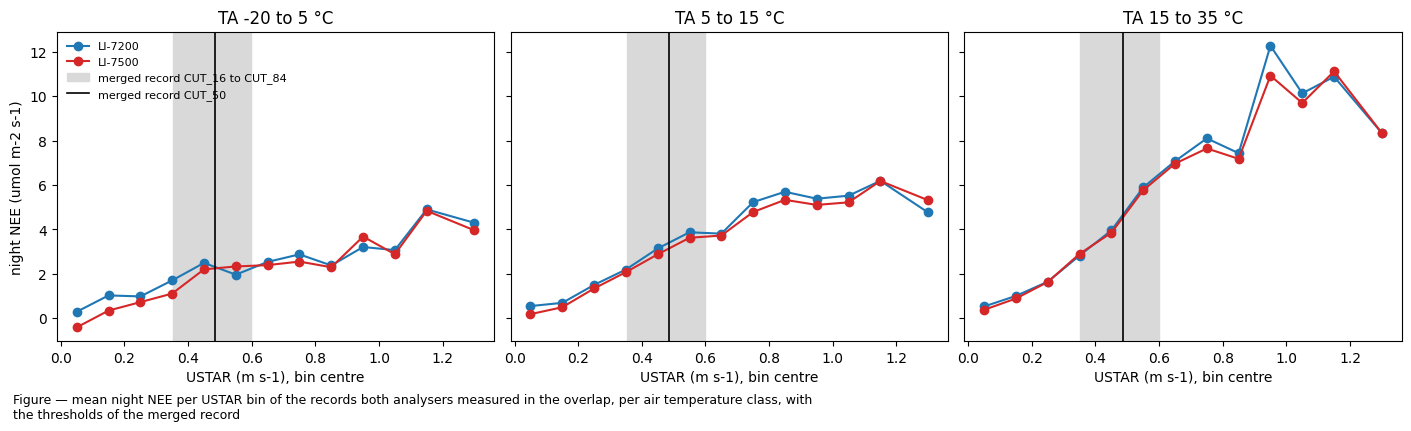

In [44]:
fig, axes = plt.subplots(1, len(_tb) - 1, figsize=(14, 4.2), layout='constrained', sharey=True)
for _ax, _tc in zip(axes, shared_curves.index.get_level_values(0).unique()):
    _c = shared_curves.xs(_tc, level=0)
    _x = [min(u.mid, 1.3) for u in _c.index]  # the last bin, above 1.2, drawn at 1.3
    for _col, _clr in (('LI-7200', 'C0'), ('LI-7500', 'C3')):
        _ax.plot(_x, _c[_col], marker='o', color=_clr, label=_col)
    _ax.axvspan(merged_cut[0], merged_cut[2], color='0.85', zorder=0, label='merged record CUT_16 to CUT_84')
    _ax.axvline(merged_cut[1], color='k', lw=1.2, label='merged record CUT_50')
    _ax.set_title(f"TA {_tc.left:.0f} to {_tc.right:.0f} °C")
    _ax.set_xlabel('USTAR (m s-1), bin centre')
axes[0].set_ylabel('night NEE (umol m-2 s-1)')
axes[0].legend(frameon=False, fontsize=8, loc='upper left')
figcap(fig, "mean night NEE per USTAR bin of the records both analysers measured in the overlap, per air "
            "temperature class, with the thresholds of the merged record")
plt.show()

Night `NEE` rises with `USTAR` in the same way in both analysers. Above 0.5 m s⁻¹ they differ by less
than 0.5 µmol m⁻² s⁻¹ in all but one bin with few records. Below 5 °C the LI-7500 lies 0.3 to
0.7 µmol m⁻² s⁻¹ lower at `USTAR` below 0.5 m s⁻¹; this would raise its threshold, not lower it.

## 📋 Table: kept night records after calm hours

In [45]:
if CHAIN_AVAILABLE:
    _rows = {}
    for _a, _d in data.items():
        _d = _d.loc[str(COMPLETE_YEARS[_a][0]):str(COMPLETE_YEARS[_a][1])]
        _prev = _d[USTAR].shift(1).rolling(2 * PREVIOUS_HOURS, min_periods=PREVIOUS_HOURS + 1).mean()
        _night = _d[(_d[SW_IN] < NIGHT_SW_IN)].assign(prev=_prev).dropna(subset=[NEE, USTAR, 'prev',
                                                                                 'RECO_NT_OF_CUT_50'])
        for _set, _cut in (('merged record', merged_cut[1]), ('own set', USTAR_THRESHOLDS[_a][1])):
            _kept = _night[_night[USTAR] >= _cut]
            for _lab, _x in (('after calm hours', _kept[_kept['prev'] < _cut]),
                             ('after mixed hours', _kept[_kept['prev'] >= _cut])):
                _rows[(ANALYSERS[_a], f"{_set}, CUT_50 {_cut:.3f}", _lab)] = {
                    'n': len(_x), 'share of night records kept': len(_kept) / len(_night),
                    'NEE / RECO_NT': _x[NEE].mean() / _x['RECO_NT_OF_CUT_50'].mean(),
                    'NEE - RECO_NT': (_x[NEE] - _x['RECO_NT_OF_CUT_50']).mean(), 'storage term': _x[STORAGE].mean()}
    calm_table = pd.DataFrame(_rows).T
    display(styled(calm_table, caption=f"night records kept at CUT_50 of the merged record and of the analyser's own "
                                       f"set, split by the mean USTAR of the previous {PREVIOUS_HOURS} hours (below or "
                                       f"at least the threshold): their number, the share of night records with NEE "
                                       f"that the threshold keeps, the ratio and difference of NEE to RECO_NT of the "
                                       f"chain run, and the mean storage term (umol m-2 s-1)",
                   fmt={'n': "{:,.0f}", 'share of night records kept': "{:.1%}"}, cmap=None))
else:
    print("Skipped: needs the results of the full chain (05 outputs).")

Table — night records kept at CUT_50 of the merged record and of the analyser's own set, split by
the mean USTAR of the previous 3 hours (below or at least the threshold): their number, the share of
night records with NEE that the threshold keeps, the ratio and difference of NEE to RECO_NT of the
chain run, and the mean storage term (umol m-2 s-1)



Kept night records that follow calm hours lie below `RECO_NT` (ratio 0.92 to 0.96 at the `CUT_50` of
the merged record), those after mixed hours at or above it (1.02 to 1.10). Right above the threshold,
the records after a calm period are therefore low rather than high, and no release of stored CO2
shows; the flush of section 10 appears only at high `USTAR`. The merged set keeps 38 % (LI-7200) and
35 % (LI-7500) of the night records with `NEE`, against 34 % and 41 % with the analysers' own sets.

</br>

# Conclusion and open points

**Decided for FP2026.2**

- The USTAR thresholds come from the ONEFlux moving point method, one set per analyser. They are
  used as constant thresholds (`CUT_16`, `CUT_50`, `CUT_84`) and written as fixed values into the
  chain notebooks. This notebook checks them against a new detection after each rerun of Level 3.2.
- The moving point method is chosen because, of the ONEFlux methods, it gives the lowest threshold at
  this site. The aim is to keep as many records as can be defended.
- The filter applies by day and by night.
- One constant set of thresholds per analyser: the thresholds of single years differ by no more
  than their bootstrap spread. Pooling years or seasons before the detection is not used, because
  it raises the threshold or makes the detection fail, without a plateau to define it.

**Open**

- One set for both analysers from the merged record (section 11): 0.352, 0.486 and 0.599 m s⁻¹, in
  place of the per-analyser sets. Applying it means changing `USTAR_THRESHOLDS` in both 05 notebooks
  and rerunning the chains.
- Night `NEE` still rises above the thresholds. Whether this is flux the tower misses or efflux drawn
  out by wind is not resolved; independent respiration data would help to decide. The respiration of the daytime partitioning
  cannot decide this: it takes its temperature sensitivity from the filtered night records and moves
  with the threshold applied in the chain. Part of the excess of night `NEE` at high `USTAR` may be
  CO2 flushed from the canopy air, which the storage term from one height does not capture.
- The thresholds rest on Level 3.2 of the chain runs listed under Prepare the input. After a rerun of Level
  3.2 the check in section 2 shows whether they still hold.

</br>

# End of notebook

In [46]:
_dt = datetime.now() - NOTEBOOK_START
print(f"Finished {datetime.now():%Y-%m-%d %H:%M:%S}; runtime {_dt.total_seconds() / 60:.1f} min")

Finished 2026-11-01 20:20:58; runtime 2.0 min
